# XJTU-SY 모델 비교와 대표 운영 규칙

팀 공유용 1~10번 분석임. Z-score·MD 규칙과 수정한 P 정의를 유지하고, IF는 6변수 통합·트리100·직접 임계치 ddof=1로 갱신함.

10번의 결론을 **최적 모델 선정이 아닌 대표 운영 규칙 선정**으로 구분함.

**대표 운영 규칙: N=20 · 연속 4회 · 고정 복합 B 방식 2/3.**
초기 상한을 넘는 변화가 같은 축의 여러 특징에서 반복 확인되는 상황을 운영 경보로 삼음.
선행시간·지속률 수치가 가장 높은 모델이라는 의미가 아님.
실제 결함 시작 라벨이 없으므로 고장 탐지 정확도나 최적성은 확정하지 않음.

CSV 10개는 프로젝트의 `results/xjtu_operating_rule/`, PNG 12개는 `figures/xjtu_operating_rule/`에 저장함.
8번은 N15·20 공통 집단, 9번은 원본 MD·증가분 MD·고정 B 2/3,
10번은 전체 비교와 대표 운영 규칙의 근거임.


## 계산 기준

- 입력 특징은 RMS·첨도·Peak의 수평/수직 6개임. 베어링 ID와 측정번호는 식별·정렬에 사용함.
- Baseline 검증: N=5~50, 수평/수직 RMS·첨도 네 항목 모두 MK p≥0.01.
  p≥0.01은 단조 추세를 검출하지 못했다는 뜻이며 정상성·정밀도 인증이 아님.
  이 MK 검정은 동률·연속성 보정을 사용하되 자기상관 보정은 하지 않음.
- N20과 K4는 팀의 공통 비교 설정임. 모든 N·K를 탐색해 얻은 보편적 최적값이 아님.
- 고정 상한: 초기 평균 + 3×표본 표준편차(ddof=1). 현재값이 상한보다 클 때 초과임.
- Moving: 현재값을 제외한 직전 N개로 기준을 매번 갱신하며 경보 후에도 갱신함.
- B m/3: 특징별 연속 K회 충족 → 같은 축에서 m개 이상 충족 → H/V OR.
  서로 다른 축의 특징을 합치거나, 매 시점 바뀌는 특징을 하나의 연속 이력으로 세지 않음.
- 누적은 감시 시작부터의 초과 횟수 합이며, 미초과 시 초기화하지 않음.
- P는 K번째 확인 완료 측정번호임. 35·36·37·38번째가 연속 초과이면 P=38(0-based index 37).
- 선행시간은 마지막 관측 시각과 P의 차이임. 실제 결함 발생·고장까지 남은 시간이 아님.
- 지속률은 P부터 종료까지 **횟수 조건을 적용하기 전의 시점별 이상** 비율임.
  확정 경보를 계속 켜 두는 비율이 아님. Z-score·MD 계열은 H/V OR, IF는 통합 이상 조건을 사용함.
  축별 모델에서 최초 경보축이 H+V이면 최초축 지속률은 두 축 지속률의 평균임.
- IF는 수평·수직 6개 특징을 **하나의 모델**에 입력함. 초기 N개로 표준화(ddof=1),
  트리100·max_samples=N·seed42로 학습함. 직접 상한은 초기 이상 점수 평균 + 3×표본SD(ddof=1)임.
  IF 지속률은 통합 점수의 시점별 이상 비율이며 축별 OR가 아님. 최초 경보축은 적용 불가, 축별 지표는 미산출임.
  자동 판정은 6번에서만 비교하고, 7~10번의 IF는 직접 3σ 상한 방식임.
- 원본 MD는 초기 평균에서의 증감과 특징 조합 변화를 모두 탐지함.
  증가분 MD는 `Z=(현재값−초기평균)/초기SD`의 `max(Z,0)`을 원래 공분산에 적용함.
  **전 시점 대비 증가량이나 시간 추세 검정이 아님.**
  기존 F 상한을 유지한 비교용 수정이며 동일한 오경보 확률은 보장되지 않음.
- 미경보도 집단에 남김. 전원 경보가 없으면 전체 집단의 최소·평균 지표는 미산출로 두고,
  경보가 난 베어링만의 조건부 지표를 별도 컬럼에 남김.
- 6번 IF 비교는 N15 통과 8개·N20 통과 6개를 각각 대상으로 K=1~8, N+1번째부터 감시함.
- 8번 N15·20 비교는 공통 통과 6개와 감시 시작 21번째를 동일하게 맞춤.


## 공통 함수와 설정

In [ ]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
from scipy import stats
from scipy.linalg import cholesky, solve_triangular
from sklearn.ensemble import IsolationForest
import sklearn
import scipy
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

FEATURES = ['rms', 'kurtosis', 'peak']
AXES = ['horizontal', 'vertical']
FEATURE_COLUMNS = [f'{axis}_{feature}' for axis in AXES for feature in FEATURES]
MK_ALPHA = 0.01
Z_LIMIT = 3.0
RANDOM_STATE = 42
IF_TREES = 100
IF_THRESHOLD_DDOF = 1
PRIMARY_N = 20
PRIMARY_K = 4
MINUTES_PER_OBSERVATION = 1
MD_ALPHA = float(stats.norm.sf(Z_LIMIT))

In [ ]:
def validate_input(data):
    """측정번호와 6개 특징을 검사함. 결측/중복/불연속 자료는 임의 보간하지 않음."""
    required = ['bearing', 'timestamp', *FEATURE_COLUMNS]
    missing = set(required) - set(data.columns)
    if missing:
        raise ValueError(f'필수 컬럼 누락: {sorted(missing)}')
    out = data[required].sort_values(['bearing', 'timestamp']).reset_index(drop=True)
    if out.empty or out[required].isna().any().any():
        raise ValueError('입력 자료가 비었거나 필수 값이 누락됨')
    if out.duplicated(['bearing', 'timestamp']).any():
        raise ValueError('베어링/측정번호 중복')
    if not np.isfinite(out[FEATURE_COLUMNS].to_numpy(dtype=float)).all():
        raise ValueError('특징에 비유한 값이 있음')
    for bearing, group in out.groupby('bearing'):
        if not np.array_equal(group.timestamp.to_numpy(), np.arange(1, len(group)+1)):
            raise ValueError(f'{bearing}: 1부터 연속된 측정번호가 필요함')
    return out


def mk_pvalue(values):
    """기존 팀 기준: 동률 및 연속성 보정, 양측 정규근사 MK 검정.

    자기상관 보정 검정이 아님. p>=0.01은 정상/정밀도 인증이 아님.
    """
    x = np.asarray(values, dtype=float)
    n = len(x)
    if n < 2 or not np.isfinite(x).all():
        raise ValueError('MK 검정에는 유한한 관측값 2개 이상이 필요함')
    s = sum(np.sign(x[i+1:] - x[i]).sum() for i in range(n-1))
    counts = np.unique(x, return_counts=True)[1]
    variance = (n*(n-1)*(2*n+5) - np.sum(counts*(counts-1)*(2*counts+5))) / 18
    z = (s - np.sign(s)) / np.sqrt(variance) if variance > 0 else 0.0
    return float(2 * stats.norm.sf(abs(z)))


def baseline_scan(data, candidates=range(5, 51)):
    """모든 N에서 전체 베어링을 유지함. 자료 부족은 미산출로 구별함."""
    rows = []
    for n in candidates:
        for bearing, group in data.groupby('bearing', sort=True):
            row = dict(bearing=bearing, baseline_n=int(n), available_observations=len(group))
            checks = {}
            for axis in AXES:
                for feature in FEATURES[:2]:
                    col = f'{axis}_{feature}'
                    checks[col+'_mk_p'] = mk_pvalue(group[col].iloc[:n]) if len(group) >= n else np.nan
            row.update(checks)
            reasons = [name.removesuffix('_mk_p') for name, p in checks.items() if p < MK_ALPHA]
            row.update(baseline_pass=len(group) >= n and not reasons,
                       baseline_state='insufficient_data' if len(group) < n else ('pass' if not reasons else 'fail'),
                       baseline_fail_reason='insufficient_data' if len(group) < n else ';'.join(reasons))
            rows.append(row)
    return pd.DataFrame(rows)

In [ ]:
def fit_scores(values, n):
    """관측×축×특징(3개). 학습/상한 적합에는 최초 N개만 사용함.

    Moving만 직전 N개로 갱신함. 현재값/미래값은 이동 기준에 들어가지 않음.
    MD는 기존 축별 공분산/예측 F 상한, IF는 6개 특징의 단일 통합 모델을 사용함.
    """
    x = np.asarray(values, dtype=float)
    if x.ndim != 3 or x.shape[1:] != (2, 3) or len(x) <= n or n <= 3:
        raise ValueError('N>3, 관측 수>N, 관측×2축×3특징 배열이 필요함')
    mu, sd = x[:n].mean(0), x[:n].std(0, ddof=1)
    if not np.isfinite(x).all() or (sd <= 0).any():
        raise ValueError('비유한 값 또는 초기 표준편차 0: 계산을 중단함')
    fixed_z = (x-mu)/sd
    # pandas의 이동 집계에 현재 관측이 섞이지 않도록 반드시 shift(1) 적용함.
    past = pd.DataFrame(x.reshape(len(x), -1)).shift(1).rolling(n, min_periods=n)
    moving_mu = past.mean().to_numpy().reshape(x.shape)
    moving_sd = past.std(ddof=1).to_numpy().reshape(x.shape)
    if (moving_sd[n:] <= 0).any() or not np.isfinite(moving_sd[n:]).all():
        raise ValueError('이동창 표준편차가 0이거나 계산 불가능함')
    moving_z = (x-moving_mu)/moving_sd
    # d=3인 새 개별 관측의 D² 상한. 정규성/독립성 가정하의 참조 상한임.
    d = 3
    md_upper = float(d*(n+1)*(n-1)/(n*(n-d)) * stats.f.isf(MD_ALPHA, d, n-d))
    md_scores, md_positive, diagnostics = [], [], []
    for a, axis in enumerate(AXES):
        z = fixed_z[:, a, :]
        covariance = np.cov(z[:n], rowvar=False, ddof=1)
        # 역행렬 대신 Cholesky 풀이. 특이행렬이면 기준을 바꾸지 않고 실패를 알림.
        lower = cholesky(covariance, lower=True)
        whitened = solve_triangular(lower, z.T, lower=True)
        md_scores.append(np.sum(whitened**2, axis=0))
        # 초기 평균 이하의 편차를 0으로 처리함. 시간 차분/상승 추세가 아님.
        # 공분산과 F 상한은 원래 값을 유지한 비교용 규칙이며 재보정된 단측 검정은 아님.
        positive_white = solve_triangular(lower, np.maximum(z, 0).T, lower=True)
        md_positive.append(np.sum(positive_white**2, axis=0))
        diagnostics.append(dict(diagnostic_model='mahalanobis', axis=axis,
            md_upper_d2=md_upper, covariance_condition_number=float(np.linalg.cond(covariance))))

    # [IF 수정] 축별 모델을 만들지 않고 수평·수직 6개 특징을 한 모델에 입력함.
    integrated_z = fixed_z.reshape(len(x), 6)
    model = IsolationForest(n_estimators=IF_TREES, max_samples=n,
                            contamination='auto', random_state=RANDOM_STATE, n_jobs=1)
    model.fit(integrated_z[:n])
    # sklearn 점수는 낮을수록 이상이므로 부호를 바꿔 상한 방식으로 통일함.
    anomaly_score = -model.score_samples(integrated_z)
    training_score = anomaly_score[:n]
    training_sd = float(training_score.std(ddof=IF_THRESHOLD_DDOF))
    limit = float(training_score.mean() + Z_LIMIT*training_sd)
    auto = model.predict(integrated_z) == -1
    np.testing.assert_array_equal(auto, anomaly_score > -model.offset_)
    diagnostics.append(dict(diagnostic_model='isolation_forest', axis='integrated',
        if_feature_count=6, if_n_estimators=IF_TREES, if_threshold_ddof=IF_THRESHOLD_DDOF,
        if_auto_upper=float(-model.offset_), if_3sigma_upper=limit,
        if_training_score_mean=float(training_score.mean()), if_training_score_sd=training_sd,
        if_training_auto_abnormal_pct=float(auto[:n].mean()*100),
        if_monitoring_auto_abnormal_pct=float(auto[n:].mean()*100),
        if_max_monitoring_score=float(anomaly_score[n:].max()),
        if_3sigma_never_exceeded=bool((anomaly_score[n:] <= limit).all())))
    return dict(fixed=fixed_z, moving=moving_z, mean=mu, sd=sd,
                moving_mean=moving_mu, moving_sd=moving_sd,
                md=np.column_stack(md_scores), md_positive=np.column_stack(md_positive), md_upper=md_upper,
                if_score=anomaly_score[:, None], if_auto=auto[:, None],
                if_upper=np.array([limit]), diagnostics=diagnostics)


In [ ]:
def count_conditions(flags, start, mode):
    """초기구간은 세지 않음. 누적은 전체 감시기간 합, 연속은 미초과 시 0으로 복귀함."""
    flags = np.asarray(flags, dtype=bool)
    counts = np.zeros(flags.shape, dtype=int)
    if mode == 'cumulative':
        counts[start:] = flags[start:].cumsum(axis=0)
    elif mode == 'consecutive':
        for i in range(start, len(flags)):
            counts[i] = np.where(flags[i], counts[i-1] + 1 if i else 1, 0)
    else:
        raise ValueError(f'알 수 없는 횟수 규칙: {mode}')
    return counts


def rule_flags(scores, detector, m, start, k, mode):
    """시점별 이상(raw)과 경보 성립(confirmed)을 분리함.

    복합 B 방식: 같은 축의 특징별 K회 충족 → m-of-3 → 마지막에 H/V OR.
    m=0은 RMS 단독을 뜻함. raw는 횟수 조건이 없는 현재 시점의 초과 여부임.
    IF의 raw/confirmed는 Nx1 통합 점수이며 H/V OR를 적용하지 않음.
    """
    if detector in ('fixed', 'moving'):
        primitive = scores[detector] > Z_LIMIT
        if m == 0:
            primitive = primitive[:, :, :1]
            required = 1
        elif m in (1, 2, 3):
            required = m
        else:
            raise ValueError('복합 특징 수는 1, 2, 3 중 하나여야 함')
    else:
        if detector == 'mahalanobis':
            raw = scores['md'] > scores['md_upper']
        elif detector == 'md_positive':
            raw = scores['md_positive'] > scores['md_upper']
        elif detector == 'if_auto':
            raw = scores['if_auto']
        elif detector == 'if_3sigma':
            raw = scores['if_score'] > scores['if_upper']
        else:
            raise ValueError(detector)
        primitive, required = raw[:, :, None], 1
    primitive = primitive.copy()
    primitive[:start] = False
    raw = primitive.sum(axis=2) >= required
    confirmed = (count_conditions(primitive, start, mode) >= k).sum(axis=2) >= required
    return raw, confirmed


def evaluate_rule(times, raw, confirmed):
    """P 이후 시점별 이상 비율. Nx2는 H/V OR, Nx1은 통합 점수이며 축 지표가 없음."""
    times = np.asarray(times)
    raw, confirmed = np.asarray(raw, dtype=bool), np.asarray(confirmed, dtype=bool)
    if (raw.ndim != 2 or raw.shape[1] not in (1, 2) or raw.shape != confirmed.shape
            or len(times) != len(raw)):
        raise ValueError('times와 길이가 같은 Nx1(통합) 또는 Nx2(H/V) 이상 배열이 필요함')
    integrated = raw.shape[1] == 1
    positions = [int(h[0]) if len(h := np.flatnonzero(confirmed[:, a])) else None
                 for a in range(raw.shape[1])]
    row = dict(t_P=np.nan, t_P_elapsed_min=np.nan, t_P_H=np.nan, t_P_V=np.nan,
               first_alarm_axis='not_applicable' if integrated else 'none',
               alarm_state='no_alarm', lead_time_min=np.nan,
               post_P_observations=0, persistence_pct=np.nan,
               first_axis_persistence_pct=np.nan, H_persistence_pct=np.nan,
               V_persistence_pct=np.nan, abnormal_observations=np.nan)
    if not integrated:
        for a, name in enumerate(['H', 'V']):
            if positions[a] is not None:
                row['t_P_'+name] = int(times[positions[a]])
    found = [p for p in positions if p is not None]
    if not found:
        return row
    p = min(found)
    selected = [a for a, position in enumerate(positions) if position == p]
    window = raw[p:]
    row.update(t_P=int(times[p]),
        t_P_elapsed_min=float((times[p]-times[0])*MINUTES_PER_OBSERVATION),
        alarm_state='alarm_at_end' if p == len(times)-1 else 'alarm_before_end',
        lead_time_min=float((times[-1]-times[p])*MINUTES_PER_OBSERVATION),
        post_P_observations=len(window), abnormal_observations=int(window.any(1).sum()),
        persistence_pct=float(window.any(1).mean()*100))
    if not integrated:
        row.update(first_alarm_axis='+'.join(['H', 'V'][a] for a in selected),
            # 동시 최초경보면 H/V 지속률의 산술평균을 사용함. OR 비율과 다를 수 있음.
            first_axis_persistence_pct=float(window[:, selected].mean()*100),
            H_persistence_pct=float(window[:, 0].mean()*100),
            V_persistence_pct=float(window[:, 1].mean()*100))
    return row


def model_label(detector, m):
    if detector in ('fixed', 'moving'):
        feature = 'RMS' if m == 0 else f'B {m}/3'
        return ('고정 ' if detector == 'fixed' else '이동 ') + feature
    return {'mahalanobis':'원본 MD', 'md_positive':'증가분 MD', 'if_auto':'통합 IF auto', 'if_3sigma':'통합 IF 3sigma'}[detector]


def build_results(data, cache, bearings, n, specifications, start=None):
    """specifications: (detector, m, k, mode). m은 Z-score 계열에서만 특징 개수를 뜻함.

    MD·IF에서 m=3은 기존 명세 식별값이며 3-of-3 조건을 적용하지 않음.
    """
    rows = []
    start = n if start is None else start
    for bearing in sorted(bearings):
        times = data.loc[data.bearing.eq(bearing), 'timestamp'].to_numpy()
        for detector, m, k, mode in specifications:
            raw, confirmed = rule_flags(cache[bearing, n], detector, m, start, k, mode)
            row = dict(bearing=bearing, baseline_n=n, monitoring_start_observation=start+1,
                       detector=detector, model=model_label(detector, m), m_of_3=m,
                       k=k, alarm_mode=mode, end_observation=int(times[-1]),
                       signal_combination='integrated' if detector.startswith('if_') else 'H/V OR')
            row.update(evaluate_rule(times, raw, confirmed))
            rows.append(row)
    return pd.DataFrame(rows)

In [ ]:
GROUP_KEYS = ['baseline_n', 'monitoring_start_observation', 'detector', 'model', 'm_of_3', 'k', 'alarm_mode']


def summarize_results(details):
    """미경보가 있으면 전체 집단 지표는 미산출. 경보군 지표는 conditional_로 표시함."""
    rows = []
    metrics = [('min_lead_time_min', 'lead_time_min', 'min'),
               ('mean_lead_time_min', 'lead_time_min', 'mean'),
               ('min_persistence_pct', 'persistence_pct', 'min'),
               ('mean_persistence_pct', 'persistence_pct', 'mean'),
               ('min_first_axis_persistence_pct', 'first_axis_persistence_pct', 'min'),
               ('mean_first_axis_persistence_pct', 'first_axis_persistence_pct', 'mean')]
    for key, group in details.groupby(GROUP_KEYS, dropna=False, sort=False):
        alarmed = group[group.alarm_state.ne('no_alarm')]
        row = dict(zip(GROUP_KEYS, key))
        row["signal_combination"] = "integrated" if row["detector"].startswith("if_") else "H/V OR"
        row.update(population=len(group), alarmed_count=len(alarmed),
                   no_alarm_count=int(group.alarm_state.eq('no_alarm').sum()),
                   alarm_at_end_count=int(group.alarm_state.eq('alarm_at_end').sum()),
                   all_before_end=bool(group.alarm_state.eq('alarm_before_end').all()))
        for name, col, operation in metrics:
            value = getattr(alarmed[col], operation)() if len(alarmed) else np.nan
            row['conditional_'+name] = value
            row[name] = value if len(alarmed) == len(group) else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

In [ ]:
def section_table(section, details, summary=None):
    summary = summarize_results(details) if summary is None else summary
    return pd.concat([summary.assign(row_type="summary"),
                      details.assign(row_type="bearing")], ignore_index=True).assign(analysis_section=section)

SUMMARY_COLS = ["model","baseline_n","k","alarm_mode","signal_combination","population","no_alarm_count",
                "min_lead_time_min","min_persistence_pct","mean_persistence_pct",
                "min_first_axis_persistence_pct"]
DETAIL_COLS = ["bearing","model","baseline_n","k","alarm_mode","signal_combination","t_P","lead_time_min",
               "persistence_pct","first_alarm_axis","first_axis_persistence_pct",
               "t_P_H","t_P_V","alarm_state"]
LABELS = {"model":"방법","baseline_n":"N","k":"K","alarm_mode":"횟수 규칙",
          "population":"비교 수","no_alarm_count":"미경보 수","min_lead_time_min":"최소 선행(분)",
          "min_persistence_pct":"최저 지속률(%)","mean_persistence_pct":"평균 지속률(%)",
          "min_first_axis_persistence_pct":"최초축 최저(%)","bearing":"베어링",
          "t_P":"P 측정번호","lead_time_min":"선행시간(분)","persistence_pct":"이상 지속률(%)",
          "first_alarm_axis":"최초축","first_axis_persistence_pct":"최초축 지속률(%)",
          "t_P_H":"수평 P","t_P_V":"수직 P","alarm_state":"경보 결과","signal_combination":"판단 결합"}
def show_results(details):
    summary = summarize_results(details)
    view = summary[SUMMARY_COLS].rename(columns=LABELS)
    display(view.style.format(precision=2, na_rep="미산출"))
    view = details[DETAIL_COLS].rename(columns=LABELS).round(2)
    display(HTML("<details><summary>베어링별 전체 결과표</summary>" +
                 view.to_html(index=False, na_rep="미산출") + "</details>"))
    return summary

## 입력 데이터와 저장 경로

저장소 루트 또는 `notebooks/`에서 실행하면 프로젝트 경로를 자동 탐색함.
기존 분석 파일에 의존하지 않으며 아래 원본 CSV 하나를 읽음.
`results/xjtu_operating_rule/`에는 CSV, `figures/xjtu_operating_rule/`에는 PNG만 생성함.

실행 조건과 입력 해시는 `reports/xjtu_operating_rule/analysis_protocol.json`에 저장함.


In [ ]:
current = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [current, *current.parents]
    if (p/"DATA/features/XJTU_SY_total_features.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("압축 해제 폴더 또는 저장소 안에서 실행해야 함. DATA/features 원본 CSV 필요.")
DATA_ROOT = PROJECT_ROOT / "DATA" / "features" / "XJTU_SY_total_features.csv"
OUTPUT_DIR_STATS = PROJECT_ROOT / "results" / "xjtu_operating_rule"
OUTPUT_DIR_STATS.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = PROJECT_ROOT / "figures" / "xjtu_operating_rule"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
data = validate_input(pd.read_csv(DATA_ROOT, usecols=["bearing","timestamp",*FEATURE_COLUMNS]))
input_sha256 = hashlib.sha256(DATA_ROOT.read_bytes()).hexdigest()
sections, section_details, section_summaries = {}, {}, {}
print(f"입력 {len(data):,}행 / {data.bearing.nunique()}개 / 모델 특징 6개")

from matplotlib import font_manager
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter
font_candidates = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
font = next((f for f in font_candidates if f in available_fonts), "DejaVu Sans")
plt.rcParams.update({"font.family":font, "font.size":11, "axes.unicode_minus":False,
    "axes.spines.top":False,"axes.spines.right":False,"figure.facecolor":"white",
    "axes.facecolor":"white","savefig.dpi":170})
COLORS = {"reference":"#315D80","selected":"#237B69","original_md":"#9D6477",
          "positive_md":"#AD7724","moving":"#7396AF"}

def finish_plot(fig, name):
    fig.savefig(FIGURE_DIR/f"{name}.png", dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def compare_plot(summary, title, name):
    """전원 경보 지표만 표시함. 미경보를 숫자 0으로 그리지 않음."""
    s = summary.reset_index(drop=True)
    labels = [f"{r.model}  N{r.baseline_n} K{r.k}" for r in s.itertuples()]
    height = max(4.5, 0.48*len(s)+1.8)
    fig, axes = plt.subplots(1,2,figsize=(14,height),layout="constrained")
    color = [COLORS["selected"] if r.detector=="fixed" and r.m_of_3==2 else
             COLORS["original_md"] if r.detector=="mahalanobis" else
             COLORS["positive_md"] if r.detector=="md_positive" else COLORS["reference"]
             for r in s.itertuples()]
    for ax, metric, xlabel in [(axes[0],"min_lead_time_min","최소 선행시간 (실험 종료 대비 분)"),
                               (axes[1],"min_persistence_pct","베어링별 최저 지속률 (%)")]:
        values = s[metric].to_numpy()
        for i,v in enumerate(values):
            if np.isfinite(v):
                ax.barh(i,v,color=color[i],height=.56)
                ax.text(v+.5,i,f"{v:.0f}" if "lead" in metric else f"{v:.2f}%",
                        va="center",fontsize=11)
            else:
                ax.text(.5,i,f"미산출 · 미경보 {int(s.iloc[i].no_alarm_count)}/{int(s.iloc[i].population)}",
                        va="center",color="#8B6127",fontsize=10)
        ax.set_yticks(range(len(s)),labels)
        ax.invert_yaxis()
        ax.set_ylim(len(s)-0.5,-0.6)
        ax.set_xlabel(xlabel)
        valid = values[np.isfinite(values)]
        ax.set_xlim(0, 112 if "persistence" in metric else max(25,valid.max()*1.18) if len(valid) else 25)
        ax.grid(axis="x",color="#E5E9ED"); ax.set_axisbelow(True)
    fig.suptitle(title+"\n각 N의 검증 통과 집단 · 미경보 포함 · 값이 클수록 해당 지표가 높음",fontsize=15)
    finish_plot(fig,name)

def record(number, name, details, title, plot=True):
    summary = show_results(details)
    key = f"{number:02d}_{name}"
    sections[key] = section_table(key,details,summary)
    section_details[number], section_summaries[number] = details,summary
    if plot:
        compare_plot(summary,title,key)
    return summary

입력 9,216행 / 15개 / 모델 특징 6개


## 1. 초기 5~50개 MK 검증
모든 N에서 15개 베어링을 유지함. 자료가 부족한 N은 미산출이며 보유량으로 대체하지 않음.

N20 통과: ['Bearing1_5', 'Bearing2_1', 'Bearing2_2', 'Bearing2_3', 'Bearing3_2', 'Bearing3_4'] 
N15 통과: ['Bearing1_3', 'Bearing1_5', 'Bearing2_1', 'Bearing2_2', 'Bearing2_3', 'Bearing3_1', 'Bearing3_2', 'Bearing3_4'] 
공통: ['Bearing1_5', 'Bearing2_1', 'Bearing2_2', 'Bearing2_3', 'Bearing3_2', 'Bearing3_4']


,baseline_n,population,passed_count,failed_count,insufficient_count,pass_rate_all_bearings_pct
0,5,15,15,0,0,100.000000
1,6,15,14,1,0,93.333333
2,7,15,13,2,0,86.666667
3,8,15,12,3,0,80.000000
4,9,15,8,7,0,53.333333
5,10,15,7,8,0,46.666667
6,11,15,8,7,0,53.333333
7,12,15,8,7,0,53.333333
8,13,15,6,9,0,40.000000
9,14,15,5,10,0,33.333333


,bearing,baseline_n,available_observations,horizontal_rms_mk_p,horizontal_kurtosis_mk_p,vertical_rms_mk_p,vertical_kurtosis_mk_p,baseline_pass,baseline_state,baseline_fail_reason
150,Bearing1_1,15,123,1.236220e-06,0.000113,4.950587e-05,7.650836e-04,False,fail,horizontal_rms;horizontal_kurtosis;vertical_rm...
151,Bearing1_2,15,161,2.944810e-02,0.001090,4.284804e-01,1.658567e-01,False,fail,horizontal_kurtosis
152,Bearing1_3,15,158,2.282150e-02,0.692181,3.730531e-01,3.222996e-01,True,pass,
153,Bearing1_4,15,122,7.527266e-05,0.074825,2.082132e-05,6.921808e-01,False,fail,horizontal_rms;vertical_rms
154,Bearing1_5,15,52,2.762784e-01,0.921159,7.665253e-01,2.282150e-02,True,pass,
155,Bearing2_1,15,491,9.245960e-02,0.165857,2.762784e-01,9.211587e-01,True,pass,
156,Bearing2_2,15,161,4.884223e-01,1.000000,1.000000e+00,1.982106e-01,True,pass,
157,Bearing2_3,15,533,7.665253e-01,0.921159,4.776124e-02,6.921808e-01,True,pass,
158,Bearing2_4,15,42,4.950587e-05,0.552615,3.665346e-04,1.658567e-01,False,fail,horizontal_rms;vertical_rms
159,Bearing2_5,15,339,2.944810e-02,0.047761,3.766692e-02,1.133875e-04,False,fail,vertical_kurtosis


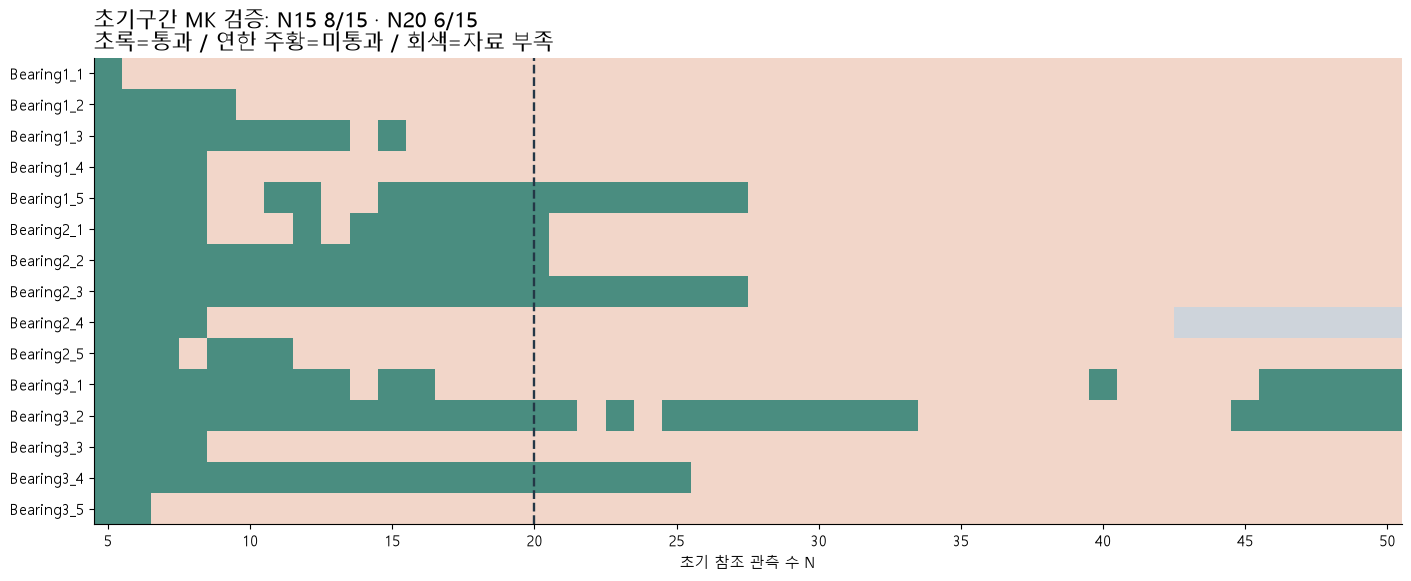

In [ ]:
baseline = baseline_scan(data)
baseline_summary = baseline.groupby("baseline_n").agg(
    population=("bearing","size"), passed_count=("baseline_pass","sum"),
    failed_count=("baseline_state",lambda x:int((x=="fail").sum())),
    insufficient_count=("baseline_state",lambda x:int((x=="insufficient_data").sum()))).reset_index()
baseline_summary["pass_rate_all_bearings_pct"] = baseline_summary.passed_count/baseline_summary.population*100
passed20 = baseline.loc[(baseline.baseline_n==20)&baseline.baseline_pass,"bearing"].tolist()
passed15 = baseline.loc[(baseline.baseline_n==15)&baseline.baseline_pass,"bearing"].tolist()
common = sorted(set(passed20)&set(passed15))
sections["01_baseline_validation"] = pd.concat([
    baseline_summary.assign(row_type="summary"),baseline.assign(row_type="bearing")],ignore_index=True)
display(baseline_summary)
display(baseline[baseline.baseline_n.isin([15,20])])
print("N20 통과:",passed20,"\nN15 통과:",passed15,"\n공통:",common)
state_map={"fail":0,"pass":1,"insufficient_data":2}
matrix=baseline.assign(state=baseline.baseline_state.map(state_map)).pivot(index="bearing",columns="baseline_n",values="state")
fig,ax=plt.subplots(figsize=(14,5.7),layout="constrained")
ax.imshow(matrix,aspect="auto",vmin=0,vmax=2,cmap=ListedColormap(["#F2D6C9","#4A8D80","#CED4DB"]))
ax.set_yticks(range(len(matrix)),matrix.index)
ticks=[5,10,15,20,25,30,35,40,45,50]
ax.set_xticks([n-5 for n in ticks],ticks)
ax.axvline(20-5,color="#243746",lw=1.7,ls="--")
ax.set_xlabel("초기 참조 관측 수 N")
ax.set_title(f"초기구간 MK 검증: N15 {len(passed15)}/15 · N20 {len(passed20)}/15\n초록=통과 / 연한 주황=미통과 / 회색=자료 부족",loc="left",fontsize=15)
finish_plot(fig,"01_baseline_validation")

# 모델은 각 베어링의 초기 자료에 한 번만 적합하여 비교 조건을 고정함.
cache, calibration_rows = {}, []
for n,bearings in [(20,passed20),(15,passed15)]:
    for bearing in bearings:
        x=data.loc[data.bearing.eq(bearing),FEATURE_COLUMNS].to_numpy().reshape(-1,2,3)
        cache[bearing,n]=fit_scores(x,n)
        calibration_rows.extend(dict(bearing=bearing,baseline_n=n,**r) for r in cache[bearing,n]["diagnostics"])
calibration=pd.DataFrame(calibration_rows)
fixed_specs=[("fixed",m,4,"consecutive") for m in range(4)]
moving_specs=[("moving",m,4,"consecutive") for m in range(4)]
md_spec=[("mahalanobis",3,4,"consecutive")]
positive_spec=[("md_positive",3,4,"consecutive")]
if_spec=[("if_3sigma",3,4,"consecutive")]

## 2. N20 고정 RMS: 누적·연속 K=1~8
누적은 감시 시작부터 총 초과 횟수, 연속은 중간 미초과에서 횟수를 초기화함.

,방법,N,K,횟수 규칙,판단 결합,비교 수,미경보 수,최소 선행(분),최저 지속률(%),평균 지속률(%),최초축 최저(%)
0,고정 RMS,20,1,cumulative,H/V OR,6,0,22.00,24.84,76.96,24.84
1,고정 RMS,20,2,cumulative,H/V OR,6,0,21.00,24.82,77.79,24.82
2,고정 RMS,20,3,cumulative,H/V OR,6,0,20.00,25.09,77.87,25.09
3,고정 RMS,20,4,cumulative,H/V OR,6,0,19.00,25.43,77.96,25.43
4,고정 RMS,20,5,cumulative,H/V OR,6,0,18.00,25.45,78.14,25.45
5,고정 RMS,20,6,cumulative,H/V OR,6,0,17.00,25.71,78.87,25.71
6,고정 RMS,20,7,cumulative,H/V OR,6,0,16.00,26.42,79.13,26.42
7,고정 RMS,20,8,cumulative,H/V OR,6,0,15.00,48.32,84.65,48.27
8,고정 RMS,20,1,consecutive,H/V OR,6,0,22.00,24.84,76.96,24.84
9,고정 RMS,20,2,consecutive,H/V OR,6,0,21.00,48.30,83.77,48.26


베어링,방법,N,K,횟수 규칙,판단 결합,P 측정번호,선행시간(분),이상 지속률(%),최초축,최초축 지속률(%),수평 P,수직 P,경보 결과
Bearing1_5,고정 RMS,20,1,cumulative,H/V OR,30,22.0,100.00,H+V,97.83,30,30,alarm_before_end
Bearing1_5,고정 RMS,20,2,cumulative,H/V OR,31,21.0,100.00,H,100.00,31,32,alarm_before_end
Bearing1_5,고정 RMS,20,3,cumulative,H/V OR,32,20.0,100.00,H,100.00,32,33,alarm_before_end
Bearing1_5,고정 RMS,20,4,cumulative,H/V OR,33,19.0,100.00,H,100.00,33,34,alarm_before_end
Bearing1_5,고정 RMS,20,5,cumulative,H/V OR,34,18.0,100.00,H,100.00,34,35,alarm_before_end
Bearing1_5,고정 RMS,20,6,cumulative,H/V OR,35,17.0,100.00,H,100.00,35,36,alarm_before_end
Bearing1_5,고정 RMS,20,7,cumulative,H/V OR,36,16.0,100.00,H,100.00,36,37,alarm_before_end
Bearing1_5,고정 RMS,20,8,cumulative,H/V OR,37,15.0,100.00,H,100.00,37,38,alarm_before_end
Bearing1_5,고정 RMS,20,1,consecutive,H/V OR,30,22.0,100.00,H+V,97.83,30,30,alarm_before_end
Bearing1_5,고정 RMS,20,2,consecutive,H/V OR,31,21.0,100.00,H,100.00,31,33,alarm_before_end


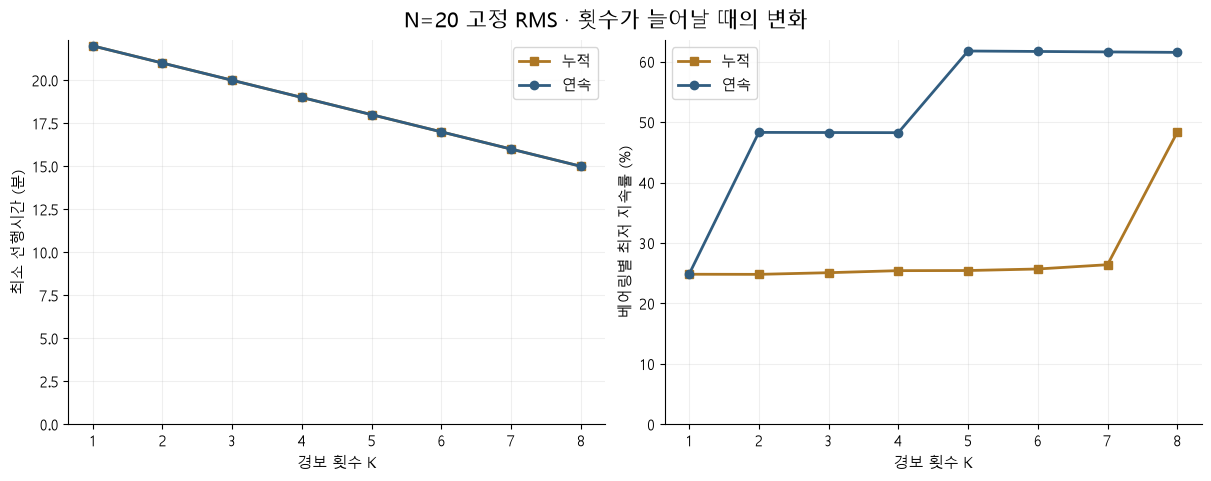

In [ ]:
rms_modes=build_results(data,cache,passed20,20,
    [("fixed",0,k,mode) for mode in ["cumulative","consecutive"] for k in range(1,9)])
s=record(2,"rms_cumulative_consecutive",rms_modes,"RMS 누적·연속",plot=False)
fig,axes=plt.subplots(1,2,figsize=(12,4.7),layout="constrained")
for mode,color,mark,label in [("cumulative","#AD7724","s","누적"),("consecutive","#315D80","o","연속")]:
    g=s[s.alarm_mode.eq(mode)].sort_values("k")
    axes[0].plot(g.k,g.min_lead_time_min,color=color,marker=mark,label=label,lw=2)
    axes[1].plot(g.k,g.min_persistence_pct,color=color,marker=mark,label=label,lw=2)
for ax,ylabel in zip(axes,["최소 선행시간 (분)","베어링별 최저 지속률 (%)"]):
    ax.set_xticks(range(1,9));ax.set_xlabel("경보 횟수 K");ax.set_ylabel(ylabel)
    ax.grid(alpha=.2);ax.legend();ax.set_ylim(bottom=0)
fig.suptitle("N=20 고정 RMS · 횟수가 늘어날 때의 변화",fontsize=15)
finish_plot(fig,"02_rms_cumulative_consecutive")

## 3. N20 K4 고정 Z: RMS 단독과 B 1/3·2/3·3/3

Out[0]: 
   baseline_n  ...  mean_first_axis_persistence_pct
0          20  ...                        85.009097
1          20  ...                        86.015179
2          20  ...                        96.326165
3          20  ...                              NaN

[4 rows x 25 columns]


,방법,N,K,횟수 규칙,판단 결합,비교 수,미경보 수,최소 선행(분),최저 지속률(%),평균 지속률(%),최초축 최저(%)
0,고정 RMS,20,4,consecutive,H/V OR,6,0,19.00,48.26,85.02,48.22
1,고정 B 1/3,20,4,consecutive,H/V OR,6,0,19.00,52.00,86.19,50.92
2,고정 B 2/3,20,4,consecutive,H/V OR,6,0,14.00,78.63,96.44,78.21
3,고정 B 3/3,20,4,consecutive,H/V OR,6,2,미산출,미산출,미산출,미산출


베어링,방법,N,K,횟수 규칙,판단 결합,P 측정번호,선행시간(분),이상 지속률(%),최초축,최초축 지속률(%),수평 P,수직 P,경보 결과
Bearing1_5,고정 RMS,20,4,consecutive,H/V OR,33.0,19.0,100.00,H,100.00,33.0,35.0,alarm_before_end
Bearing1_5,고정 B 1/3,20,4,consecutive,H/V OR,33.0,19.0,100.00,H,100.00,33.0,35.0,alarm_before_end
Bearing1_5,고정 B 2/3,20,4,consecutive,H/V OR,38.0,14.0,100.00,H+V,100.00,38.0,38.0,alarm_before_end
Bearing1_5,고정 B 3/3,20,4,consecutive,H/V OR,미산출,미산출,미산출,none,미산출,미산출,미산출,no_alarm
Bearing2_1,고정 RMS,20,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end
Bearing2_1,고정 B 1/3,20,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end
Bearing2_1,고정 B 2/3,20,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end
Bearing2_1,고정 B 3/3,20,4,consecutive,H/V OR,456.0,35.0,100.00,V,97.22,458.0,456.0,alarm_before_end
Bearing2_2,고정 RMS,20,4,consecutive,H/V OR,50.0,111.0,100.00,H+V,100.00,50.0,50.0,alarm_before_end
Bearing2_2,고정 B 1/3,20,4,consecutive,H/V OR,50.0,111.0,100.00,H+V,100.00,50.0,50.0,alarm_before_end


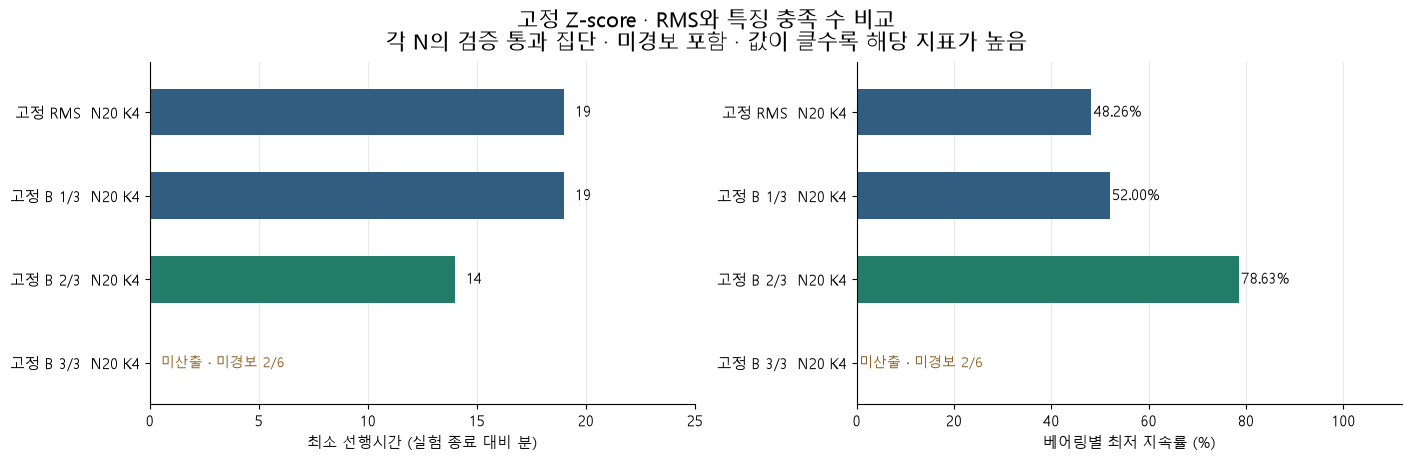

In [ ]:
fixed=build_results(data,cache,passed20,20,fixed_specs)
record(3,"fixed_single_composite",fixed,"고정 Z-score · RMS와 특징 충족 수 비교")

## 4. N20 K4 이동 Z: RMS 단독과 B 1/3·2/3·3/3
현재값은 이동창에 포함하지 않음.

Out[0]: 
   baseline_n  ...  mean_first_axis_persistence_pct
0          20  ...                              NaN
1          20  ...                              NaN
2          20  ...                              NaN
3          20  ...                              NaN

[4 rows x 25 columns]


,방법,N,K,횟수 규칙,판단 결합,비교 수,미경보 수,최소 선행(분),최저 지속률(%),평균 지속률(%),최초축 최저(%)
0,이동 RMS,20,4,consecutive,H/V OR,6,2,미산출,미산출,미산출,미산출
1,이동 B 1/3,20,4,consecutive,H/V OR,6,1,미산출,미산출,미산출,미산출
2,이동 B 2/3,20,4,consecutive,H/V OR,6,3,미산출,미산출,미산출,미산출
3,이동 B 3/3,20,4,consecutive,H/V OR,6,6,미산출,미산출,미산출,미산출


베어링,방법,N,K,횟수 규칙,판단 결합,P 측정번호,선행시간(분),이상 지속률(%),최초축,최초축 지속률(%),수평 P,수직 P,경보 결과
Bearing1_5,이동 RMS,20,4,consecutive,H/V OR,36.0,16.0,41.18,V,35.29,38.0,36.0,alarm_before_end
Bearing1_5,이동 B 1/3,20,4,consecutive,H/V OR,36.0,16.0,64.71,V,41.18,38.0,36.0,alarm_before_end
Bearing1_5,이동 B 2/3,20,4,consecutive,H/V OR,미산출,미산출,미산출,none,미산출,미산출,미산출,no_alarm
Bearing1_5,이동 B 3/3,20,4,consecutive,H/V OR,미산출,미산출,미산출,none,미산출,미산출,미산출,no_alarm
Bearing2_1,이동 RMS,20,4,consecutive,H/V OR,455.0,36.0,21.62,H,16.22,455.0,456.0,alarm_before_end
Bearing2_1,이동 B 1/3,20,4,consecutive,H/V OR,455.0,36.0,24.32,H,21.62,455.0,456.0,alarm_before_end
Bearing2_1,이동 B 2/3,20,4,consecutive,H/V OR,456.0,35.0,13.89,H+V,8.33,456.0,456.0,alarm_before_end
Bearing2_1,이동 B 3/3,20,4,consecutive,H/V OR,미산출,미산출,미산출,none,미산출,미산출,미산출,no_alarm
Bearing2_2,이동 RMS,20,4,consecutive,H/V OR,84.0,77.0,14.10,H,14.10,84.0,미산출,alarm_before_end
Bearing2_2,이동 B 1/3,20,4,consecutive,H/V OR,51.0,110.0,20.72,H,17.12,51.0,미산출,alarm_before_end


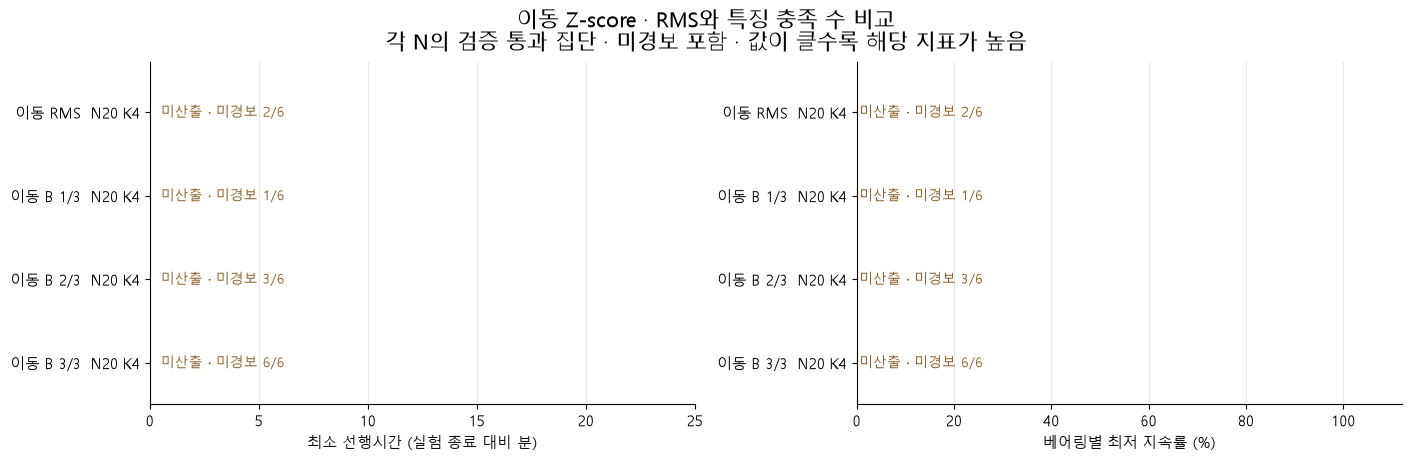

In [ ]:
moving=build_results(data,cache,passed20,20,moving_specs)
record(4,"moving_single_composite",moving,"이동 Z-score · RMS와 특징 충족 수 비교")

## 5. N20 K4 고정 단독·복합과 원본 마할라노비스
원본 MD는 감소도 탐지함. 이 차이를 알고 비교해야 함.

Out[0]: 
   baseline_n  ...  mean_first_axis_persistence_pct
0          20  ...                        85.009097
1          20  ...                        86.015179
2          20  ...                        96.326165
3          20  ...                              NaN
4          20  ...                        96.611850

[5 rows x 25 columns]


,방법,N,K,횟수 규칙,판단 결합,비교 수,미경보 수,최소 선행(분),최저 지속률(%),평균 지속률(%),최초축 최저(%)
0,고정 RMS,20,4,consecutive,H/V OR,6,0,19.00,48.26,85.02,48.22
1,고정 B 1/3,20,4,consecutive,H/V OR,6,0,19.00,52.00,86.19,50.92
2,고정 B 2/3,20,4,consecutive,H/V OR,6,0,14.00,78.63,96.44,78.21
3,고정 B 3/3,20,4,consecutive,H/V OR,6,2,미산출,미산출,미산출,미산출
4,원본 MD,20,4,consecutive,H/V OR,6,0,17.00,84.08,96.94,82.79


베어링,방법,N,K,횟수 규칙,판단 결합,P 측정번호,선행시간(분),이상 지속률(%),최초축,최초축 지속률(%),수평 P,수직 P,경보 결과
Bearing1_5,고정 RMS,20,4,consecutive,H/V OR,33.0,19.0,100.00,H,100.00,33.0,35.0,alarm_before_end
Bearing1_5,고정 B 1/3,20,4,consecutive,H/V OR,33.0,19.0,100.00,H,100.00,33.0,35.0,alarm_before_end
Bearing1_5,고정 B 2/3,20,4,consecutive,H/V OR,38.0,14.0,100.00,H+V,100.00,38.0,38.0,alarm_before_end
Bearing1_5,고정 B 3/3,20,4,consecutive,H/V OR,미산출,미산출,미산출,none,미산출,미산출,미산출,no_alarm
Bearing1_5,원본 MD,20,4,consecutive,H/V OR,35.0,17.0,100.00,H,100.00,35.0,36.0,alarm_before_end
Bearing2_1,고정 RMS,20,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end
Bearing2_1,고정 B 1/3,20,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end
Bearing2_1,고정 B 2/3,20,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end
Bearing2_1,고정 B 3/3,20,4,consecutive,H/V OR,456.0,35.0,100.00,V,97.22,458.0,456.0,alarm_before_end
Bearing2_1,원본 MD,20,4,consecutive,H/V OR,83.0,408.0,99.02,H,98.53,83.0,114.0,alarm_before_end


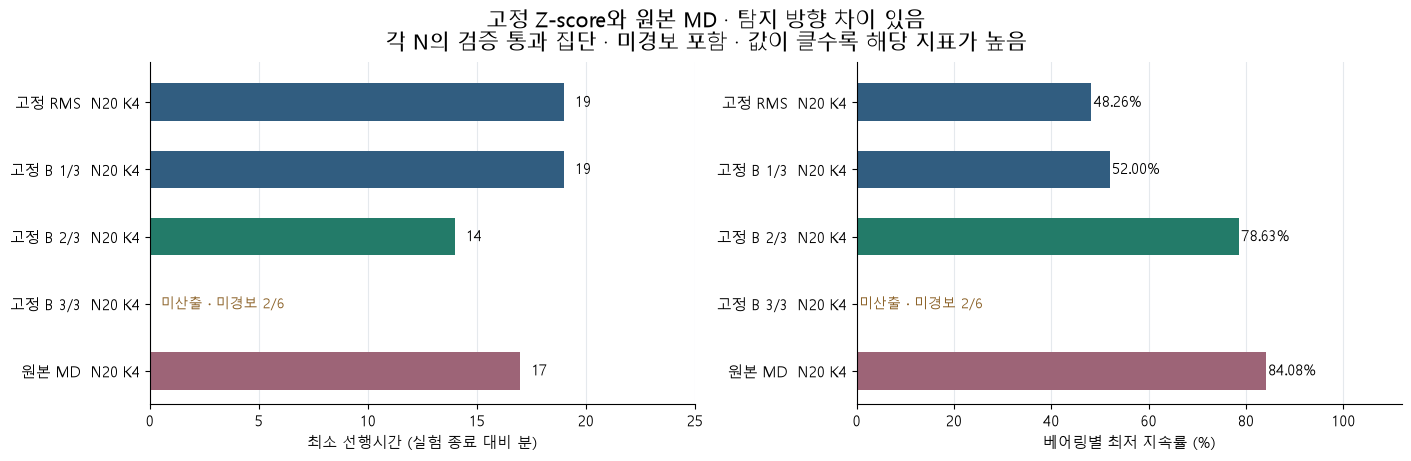

In [ ]:
with_md=build_results(data,cache,passed20,20,fixed_specs+md_spec)
record(5,"fixed_vs_mahalanobis",with_md,"고정 Z-score와 원본 MD · 탐지 방향 차이 있음")

## 6. 통합 IF 자동 판정과 직접 3σ 판정: N15·20, K=1~8

수평·수직 6개 특징을 한 모델에 입력하고 트리100·seed42·초기 표준화(ddof=1)를 사용함.
동일한 모델 점수에 자동 상한과 직접 상한(초기 점수 평균 + 3×표본SD, ddof=1)을 각각 적용함.

N15는 독립 통과 8개를 16번째부터, N20은 독립 통과 6개를 21번째부터 감시함.
따라서 이 절의 두 N 요약은 집단과 시작 시점이 다름. 동일 집단 비교는 8번을 확인함.
K=1~8이고 P는 K번째 확인 시점임. 지속률은 P부터의 통합 점수 이상 비율임.
최초 경보축과 축별 지속률은 적용 불가로 남김. 자동 판정의 초기구간 이상 비율은
학습자료 자기 평가이며 실제 오경보율이 아님.


,방법,N,K,횟수 규칙,판단 결합,비교 수,미경보 수,최소 선행(분),최저 지속률(%),평균 지속률(%),최초축 최저(%)
0,통합 IF auto,15,1,consecutive,integrated,8,0,34.00,87.20,96.61,미산출
1,통합 IF 3sigma,15,1,consecutive,integrated,8,1,미산출,미산출,미산출,미산출
2,통합 IF auto,15,2,consecutive,integrated,8,0,29.00,87.19,97.49,미산출
3,통합 IF 3sigma,15,2,consecutive,integrated,8,1,미산출,미산출,미산출,미산출
4,통합 IF auto,15,3,consecutive,integrated,8,0,28.00,87.19,97.53,미산출
5,통합 IF 3sigma,15,3,consecutive,integrated,8,1,미산출,미산출,미산출,미산출
6,통합 IF auto,15,4,consecutive,integrated,8,0,27.00,87.18,97.59,미산출
7,통합 IF 3sigma,15,4,consecutive,integrated,8,1,미산출,미산출,미산출,미산출
8,통합 IF auto,15,5,consecutive,integrated,8,0,26.00,87.18,97.67,미산출
9,통합 IF 3sigma,15,5,consecutive,integrated,8,1,미산출,미산출,미산출,미산출


베어링,방법,N,K,횟수 규칙,판단 결합,P 측정번호,선행시간(분),이상 지속률(%),최초축,최초축 지속률(%),수평 P,수직 P,경보 결과
Bearing1_3,통합 IF auto,15,1,consecutive,integrated,16.0,142.0,96.50,not_applicable,미산출,미산출,미산출,alarm_before_end
Bearing1_3,통합 IF 3sigma,15,1,consecutive,integrated,미산출,미산출,미산출,not_applicable,미산출,미산출,미산출,no_alarm
Bearing1_3,통합 IF auto,15,2,consecutive,integrated,19.0,139.0,97.14,not_applicable,미산출,미산출,미산출,alarm_before_end
Bearing1_3,통합 IF 3sigma,15,2,consecutive,integrated,미산출,미산출,미산출,not_applicable,미산출,미산출,미산출,no_alarm
Bearing1_3,통합 IF auto,15,3,consecutive,integrated,20.0,138.0,97.12,not_applicable,미산출,미산출,미산출,alarm_before_end
Bearing1_3,통합 IF 3sigma,15,3,consecutive,integrated,미산출,미산출,미산출,not_applicable,미산출,미산출,미산출,no_alarm
Bearing1_3,통합 IF auto,15,4,consecutive,integrated,21.0,137.0,97.10,not_applicable,미산출,미산출,미산출,alarm_before_end
Bearing1_3,통합 IF 3sigma,15,4,consecutive,integrated,미산출,미산출,미산출,not_applicable,미산출,미산출,미산출,no_alarm
Bearing1_3,통합 IF auto,15,5,consecutive,integrated,22.0,136.0,97.08,not_applicable,미산출,미산출,미산출,alarm_before_end
Bearing1_3,통합 IF 3sigma,15,5,consecutive,integrated,미산출,미산출,미산출,not_applicable,미산출,미산출,미산출,no_alarm


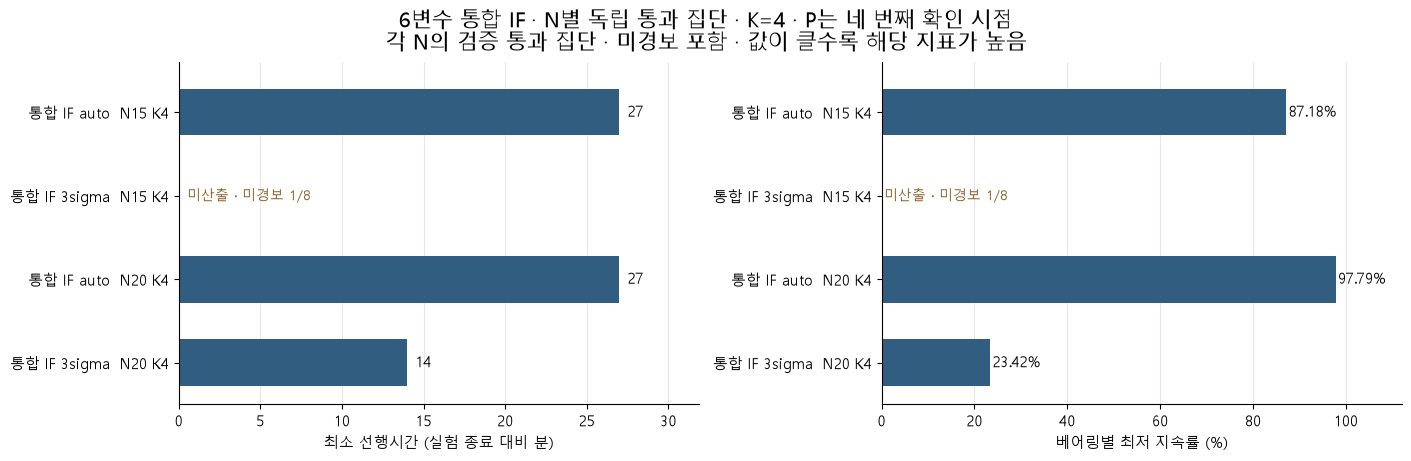

,bearing,baseline_n,diagnostic_model,axis,if_feature_count,if_n_estimators,if_threshold_ddof,if_auto_upper,if_3sigma_upper,if_training_score_mean,if_training_score_sd,if_training_auto_abnormal_pct,if_monitoring_auto_abnormal_pct,if_max_monitoring_score,if_3sigma_never_exceeded
2,Bearing1_5,20,isolation_forest,integrated,6.0,100.0,1.0,0.5,0.59973,0.47465,0.04169,30.00000,96.87500,0.67468,False
5,Bearing2_1,20,isolation_forest,integrated,6.0,100.0,1.0,0.5,0.62892,0.48294,0.04866,40.00000,99.78769,0.65344,False
8,Bearing2_2,20,isolation_forest,integrated,6.0,100.0,1.0,0.5,0.65624,0.47596,0.06009,25.00000,96.45390,0.66550,False
11,Bearing2_3,20,isolation_forest,integrated,6.0,100.0,1.0,0.5,0.60601,0.49225,0.03792,35.00000,98.44055,0.64329,False
14,Bearing3_2,20,isolation_forest,integrated,6.0,100.0,1.0,0.5,0.64633,0.47600,0.05677,30.00000,98.18255,0.67924,False
17,Bearing3_4,20,isolation_forest,integrated,6.0,100.0,1.0,0.5,0.62233,0.48250,0.04661,35.00000,99.46488,0.66367,False
20,Bearing1_3,15,isolation_forest,integrated,6.0,100.0,1.0,0.5,0.65049,0.48790,0.05420,40.00000,96.50350,0.61976,True
23,Bearing1_5,15,isolation_forest,integrated,6.0,100.0,1.0,0.5,0.62071,0.47620,0.04817,26.66667,89.18919,0.66301,False
26,Bearing2_1,15,isolation_forest,integrated,6.0,100.0,1.0,0.5,0.61917,0.49626,0.04097,46.66667,99.57983,0.62732,False
29,Bearing2_2,15,isolation_forest,integrated,6.0,100.0,1.0,0.5,0.64749,0.48804,0.05315,33.33333,100.00000,0.65336,False


In [ ]:
if_comparison=pd.concat([
    build_results(data,cache,bearings,n,
        [(detector,3,k,"consecutive") for k in range(1,9)
         for detector in ["if_auto","if_3sigma"]])
    for n,bearings in [(15,passed15),(20,passed20)]],ignore_index=True)
record(6,"isolation_forest_thresholds",if_comparison,"통합 IF 자동·직접 임계치",plot=False)
# MD 축별 공분산 진단은 섞지 않고, 통합 IF의 초기 점수·상한만 이 절에 기록함.
if_calibration=calibration[calibration.diagnostic_model.eq("isolation_forest")].dropna(axis=1,how="all")
sections["06_isolation_forest_thresholds"]=pd.concat([
    sections["06_isolation_forest_thresholds"],
    if_calibration.assign(row_type="calibration")],ignore_index=True)
compare_plot(section_summaries[6].query("k == 4"),
    "6변수 통합 IF · N별 독립 통과 집단 · K=4 · P는 네 번째 확인 시점","06_if_K4_comparison")
display(if_calibration.round(5))


## 7. N20 K4 고정 단독·복합·원본 MD·6변수 통합 IF 직접 임계치

Out[0]: 
   baseline_n  ...  mean_first_axis_persistence_pct
0          20  ...                        85.009097
1          20  ...                        86.015179
2          20  ...                        96.326165
3          20  ...                              NaN
4          20  ...                        96.611850
5          20  ...                              NaN

[6 rows x 25 columns]


,방법,N,K,횟수 규칙,판단 결합,비교 수,미경보 수,최소 선행(분),최저 지속률(%),평균 지속률(%),최초축 최저(%)
0,고정 RMS,20,4,consecutive,H/V OR,6,0,19.00,48.26,85.02,48.22
1,고정 B 1/3,20,4,consecutive,H/V OR,6,0,19.00,52.00,86.19,50.92
2,고정 B 2/3,20,4,consecutive,H/V OR,6,0,14.00,78.63,96.44,78.21
3,고정 B 3/3,20,4,consecutive,H/V OR,6,2,미산출,미산출,미산출,미산출
4,원본 MD,20,4,consecutive,H/V OR,6,0,17.00,84.08,96.94,82.79
5,통합 IF 3sigma,20,4,consecutive,integrated,6,0,14.00,23.42,69.85,미산출


베어링,방법,N,K,횟수 규칙,판단 결합,P 측정번호,선행시간(분),이상 지속률(%),최초축,최초축 지속률(%),수평 P,수직 P,경보 결과
Bearing1_5,고정 RMS,20,4,consecutive,H/V OR,33.0,19.0,100.00,H,100.00,33.0,35.0,alarm_before_end
Bearing1_5,고정 B 1/3,20,4,consecutive,H/V OR,33.0,19.0,100.00,H,100.00,33.0,35.0,alarm_before_end
Bearing1_5,고정 B 2/3,20,4,consecutive,H/V OR,38.0,14.0,100.00,H+V,100.00,38.0,38.0,alarm_before_end
Bearing1_5,고정 B 3/3,20,4,consecutive,H/V OR,미산출,미산출,미산출,none,미산출,미산출,미산출,no_alarm
Bearing1_5,원본 MD,20,4,consecutive,H/V OR,35.0,17.0,100.00,H,100.00,35.0,36.0,alarm_before_end
Bearing1_5,통합 IF 3sigma,20,4,consecutive,integrated,38.0,14.0,100.00,not_applicable,미산출,미산출,미산출,alarm_before_end
Bearing2_1,고정 RMS,20,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end
Bearing2_1,고정 B 1/3,20,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end
Bearing2_1,고정 B 2/3,20,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end
Bearing2_1,고정 B 3/3,20,4,consecutive,H/V OR,456.0,35.0,100.00,V,97.22,458.0,456.0,alarm_before_end


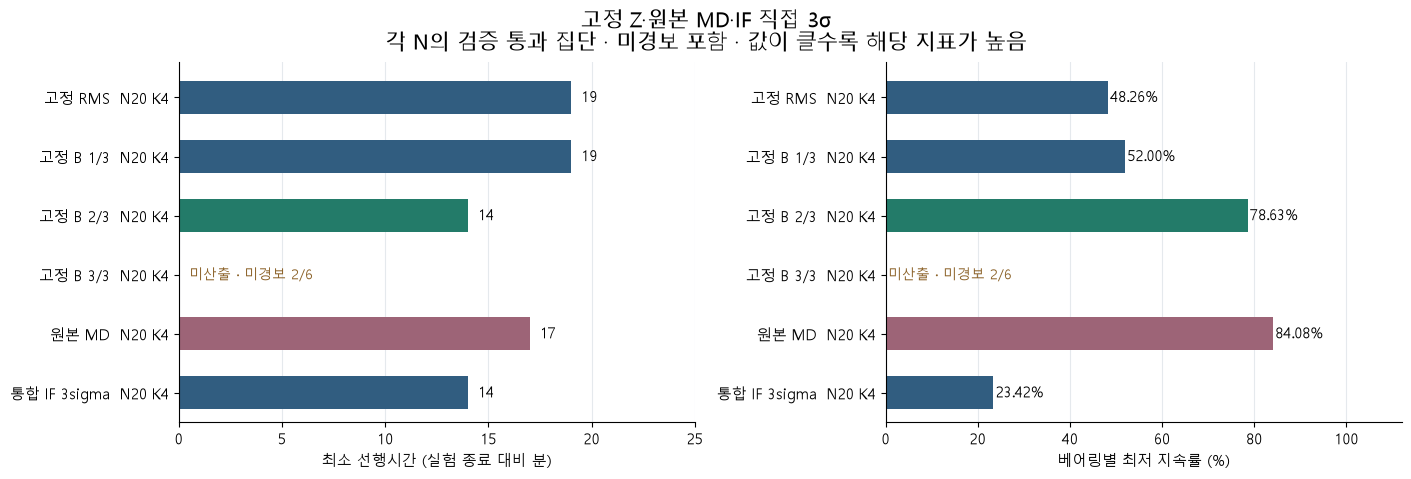

In [ ]:
overall=build_results(data,cache,passed20,20,fixed_specs+md_spec+if_spec)
record(7,"overall_direct_comparison",overall,"고정 Z·원본 MD·IF 직접 3σ")

## 8. N15·20 공통 통과 베어링 비교
두 N 모두 21번째부터 감시함. 증가분 MD도 추가하여 N 변화에 대한 반응을 비교함.
6번의 N별 독립 집단 결과와 구분함. 이 절은 두 N의 통과 교집합만 사용하고 IF도 같은 시작 시점을 적용함.


,방법,N,K,횟수 규칙,판단 결합,비교 수,미경보 수,최소 선행(분),최저 지속률(%),평균 지속률(%),최초축 최저(%)
0,고정 RMS,15,4,consecutive,H/V OR,6,0,19.00,56.36,90.46,56.36
1,고정 B 1/3,15,4,consecutive,H/V OR,6,0,19.00,59.88,91.04,59.88
2,고정 B 2/3,15,4,consecutive,H/V OR,6,0,14.00,76.08,96.01,75.60
3,고정 B 3/3,15,4,consecutive,H/V OR,6,2,미산출,미산출,미산출,미산출
4,원본 MD,15,4,consecutive,H/V OR,6,0,17.00,96.93,99.13,96.86
5,증가분 MD,15,4,consecutive,H/V OR,6,0,17.00,30.16,83.30,30.16
6,통합 IF 3sigma,15,4,consecutive,integrated,6,0,14.00,21.43,52.77,미산출
7,고정 RMS,20,4,consecutive,H/V OR,6,0,19.00,48.26,85.02,48.22
8,고정 B 1/3,20,4,consecutive,H/V OR,6,0,19.00,52.00,86.19,50.92
9,고정 B 2/3,20,4,consecutive,H/V OR,6,0,14.00,78.63,96.44,78.21


베어링,방법,N,K,횟수 규칙,판단 결합,P 측정번호,선행시간(분),이상 지속률(%),최초축,최초축 지속률(%),수평 P,수직 P,경보 결과
Bearing1_5,고정 RMS,15,4,consecutive,H/V OR,33.0,19.0,100.00,H,100.00,33.0,35.0,alarm_before_end
Bearing1_5,고정 B 1/3,15,4,consecutive,H/V OR,33.0,19.0,100.00,H,100.00,33.0,35.0,alarm_before_end
Bearing1_5,고정 B 2/3,15,4,consecutive,H/V OR,38.0,14.0,100.00,H+V,100.00,38.0,38.0,alarm_before_end
Bearing1_5,고정 B 3/3,15,4,consecutive,H/V OR,미산출,미산출,미산출,none,미산출,미산출,미산출,no_alarm
Bearing1_5,원본 MD,15,4,consecutive,H/V OR,35.0,17.0,100.00,H,100.00,35.0,36.0,alarm_before_end
Bearing1_5,증가분 MD,15,4,consecutive,H/V OR,35.0,17.0,100.00,H,100.00,35.0,36.0,alarm_before_end
Bearing1_5,통합 IF 3sigma,15,4,consecutive,integrated,38.0,14.0,86.67,not_applicable,미산출,미산출,미산출,alarm_before_end
Bearing2_1,고정 RMS,15,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end
Bearing2_1,고정 B 1/3,15,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end
Bearing2_1,고정 B 2/3,15,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end


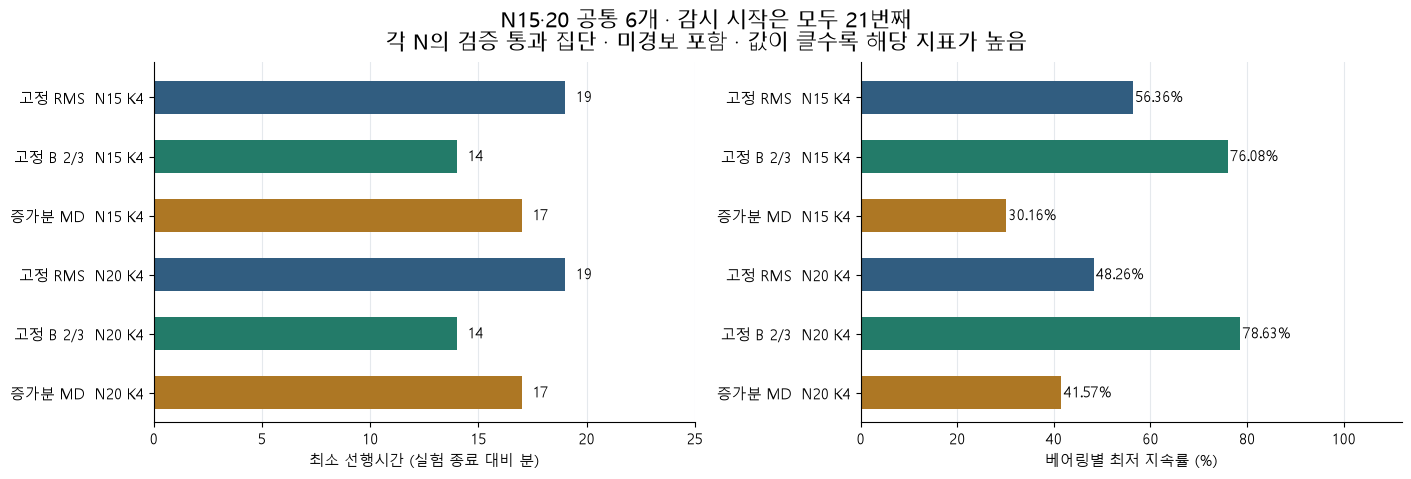

In [ ]:
common_results=pd.concat([build_results(data,cache,common,n,
    fixed_specs+md_spec+positive_spec+if_spec,start=20) for n in [15,20]],ignore_index=True)
record(8,"common_N15_N20",common_results,"N15·20 공통 집단",plot=False)
paired=common_results.query("baseline_n == 15").merge(
    common_results.query("baseline_n == 20"),on=["bearing","detector","model","m_of_3","k","alarm_mode"],
    suffixes=("_N15","_N20"),validate="one_to_one")
for col in ["t_P","lead_time_min","persistence_pct","first_axis_persistence_pct"]:
    paired[col+"_delta_N20_minus_N15"]=paired[col+"_N20"]-paired[col+"_N15"]
sections["08_common_N15_N20"]=pd.concat([sections["08_common_N15_N20"],
    paired.assign(row_type="paired_delta")],ignore_index=True)
focus=section_summaries[8][((section_summaries[8].detector=="fixed")&
    section_summaries[8].m_of_3.isin([0,2]))|section_summaries[8].detector.eq("md_positive")]
compare_plot(focus,"N15·20 공통 6개 · 감시 시작은 모두 21번째","08_common_N15_N20")

## 9. N20 K4 원본 MD·증가분 MD·고정 복합 B 2/3 비교
세 조건만 비교함. 증가분 MD는 P뿐 아니라 지속률도 증가분 기준으로 계산함.

,방법,N,K,횟수 규칙,판단 결합,비교 수,미경보 수,최소 선행(분),최저 지속률(%),평균 지속률(%),최초축 최저(%)
0,원본 MD,20,4,consecutive,H/V OR,6,0,17.00,84.08,96.94,82.79
1,증가분 MD,20,4,consecutive,H/V OR,6,0,17.00,41.57,86.55,41.57
2,고정 B 2/3,20,4,consecutive,H/V OR,6,0,14.00,78.63,96.44,78.21


베어링,방법,N,K,횟수 규칙,판단 결합,P 측정번호,선행시간(분),이상 지속률(%),최초축,최초축 지속률(%),수평 P,수직 P,경보 결과
Bearing1_5,원본 MD,20,4,consecutive,H/V OR,35,17.0,100.00,H,100.00,35,36,alarm_before_end
Bearing1_5,증가분 MD,20,4,consecutive,H/V OR,35,17.0,100.00,H,100.00,35,36,alarm_before_end
Bearing1_5,고정 B 2/3,20,4,consecutive,H/V OR,38,14.0,100.00,H+V,100.00,38,38,alarm_before_end
Bearing2_1,원본 MD,20,4,consecutive,H/V OR,83,408.0,99.02,H,98.53,83,114,alarm_before_end
Bearing2_1,증가분 MD,20,4,consecutive,H/V OR,456,35.0,100.00,H+V,100.00,456,456,alarm_before_end
Bearing2_1,고정 B 2/3,20,4,consecutive,H/V OR,456,35.0,100.00,H+V,100.00,456,456,alarm_before_end
Bearing2_2,원본 MD,20,4,consecutive,H/V OR,50,111.0,100.00,H+V,100.00,50,50,alarm_before_end
Bearing2_2,증가분 MD,20,4,consecutive,H/V OR,50,111.0,100.00,H+V,100.00,50,50,alarm_before_end
Bearing2_2,고정 B 2/3,20,4,consecutive,H/V OR,51,110.0,100.00,H+V,100.00,51,51,alarm_before_end
Bearing2_3,원본 MD,20,4,consecutive,H/V OR,29,504.0,98.61,H,98.42,29,131,alarm_before_end


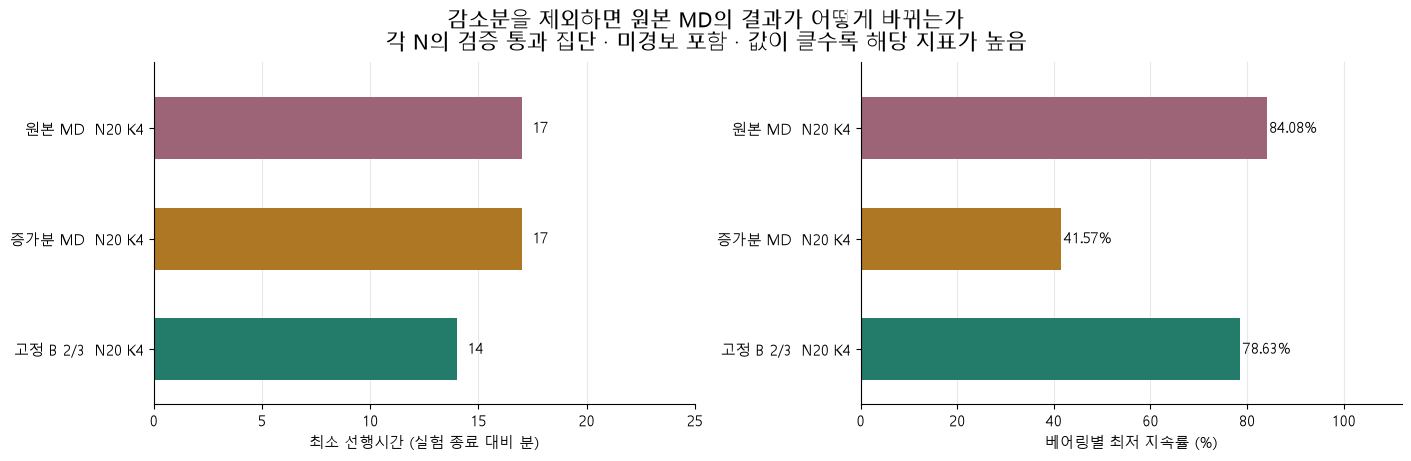

,bearing,t_P_original,t_P_positive,persistence_pct_original,persistence_pct_positive
0,Bearing1_5,35,35,100.00,100.00
1,Bearing2_1,83,456,99.02,100.00
2,Bearing2_2,50,50,100.00,100.00
3,Bearing2_3,29,131,98.61,100.00
4,Bearing3_2,562,1235,84.08,77.73
5,Bearing3_4,55,1006,99.93,41.57


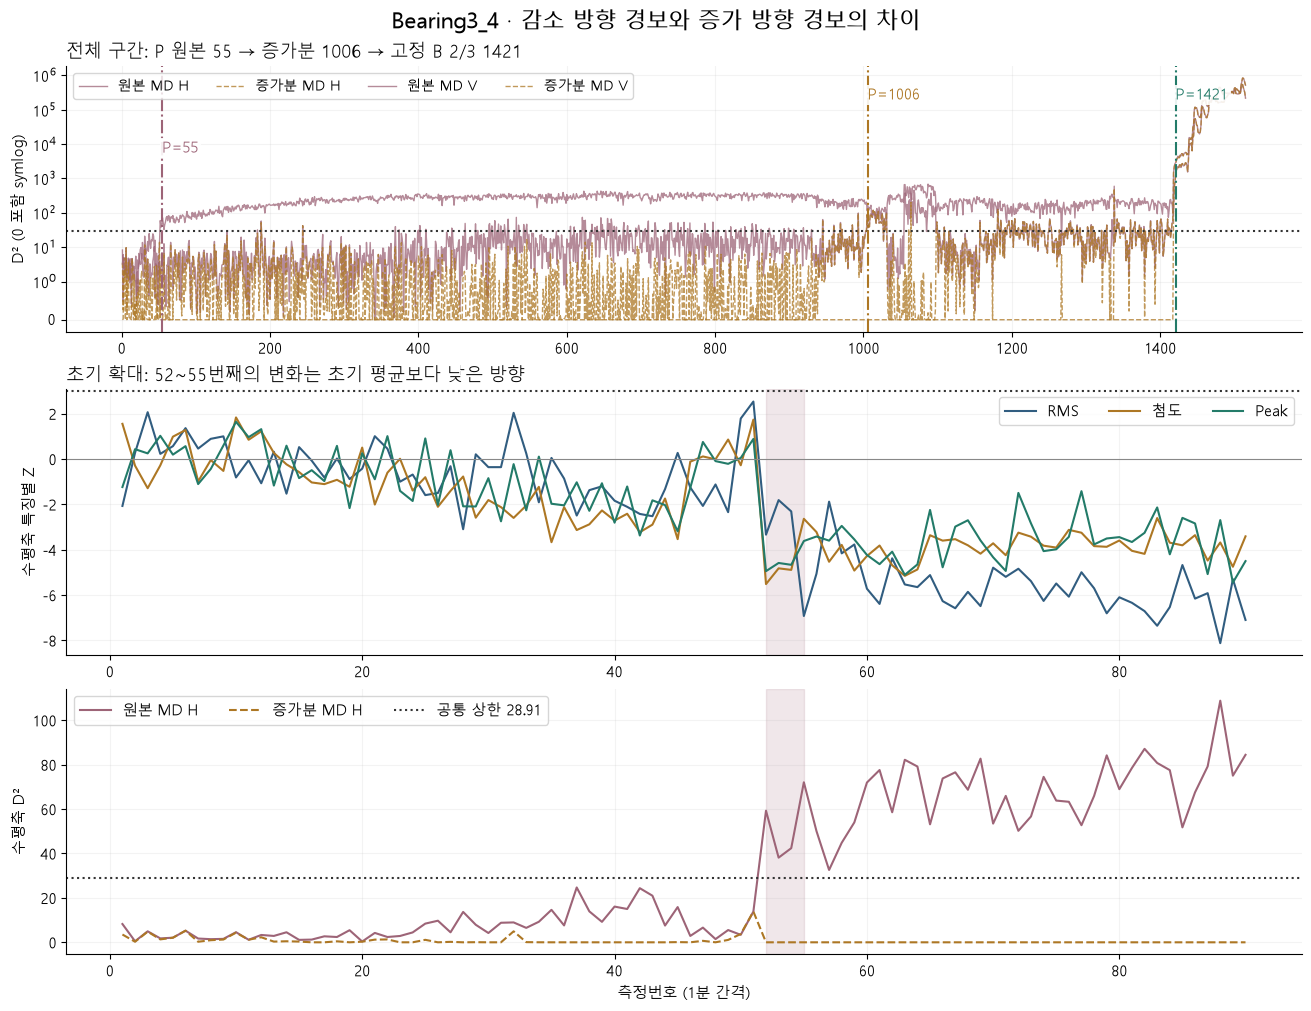

In [ ]:
md_comparison=build_results(data,cache,passed20,20,
    md_spec+positive_spec+[spec for spec in fixed_specs if spec[1]==2])
record(9,"md_direction_comparison",md_comparison,"감소분을 제외하면 원본 MD의 결과가 어떻게 바뀌는가")
md_changes=md_comparison[md_comparison.detector.eq("mahalanobis")].merge(
    md_comparison[md_comparison.detector.eq("md_positive")],on="bearing",suffixes=("_original","_positive"))
sections["09_md_direction_comparison"]=pd.concat([sections["09_md_direction_comparison"],
    md_changes.assign(row_type="direction_delta")],ignore_index=True)
display(md_changes[["bearing","t_P_original","t_P_positive",
                    "persistence_pct_original","persistence_pct_positive"]].round(2))

# 실제 감소분의 영향을 설명하는 대표 베어링. 전체 D²와 초기 확대를 함께 그림.
bearing="Bearing3_4"
sc=cache[bearing,20]
t=data.loc[data.bearing.eq(bearing),"timestamp"].to_numpy()
fig,axes=plt.subplots(3,1,figsize=(13,10),layout="constrained")
for a in range(2):
    for key,style,color in [("md","-","#9D6477"),("md_positive","--","#AD7724")]:
        axes[0].plot(t,sc[key][:,a],ls=style,color=color,alpha=.75,lw=1,
                     label=(("원본 MD" if key=="md" else "증가분 MD")+(" H" if a==0 else " V")))
axes[0].set_yscale("symlog",linthresh=1);axes[0].set_ylabel("D² (0 포함 symlog)")
axes[0].axhline(sc["md_upper"],color="#333333",ls=":")
for det,color in [("mahalanobis","#9D6477"),("md_positive","#AD7724"),("fixed","#237B69")]:
    r=md_comparison[(md_comparison.bearing==bearing)&(md_comparison.detector==det)]
    if det=="fixed":r=r[r.m_of_3.eq(2)]
    p=float(r.iloc[0].t_P)
    axes[0].axvline(p,color=color,ls="-.")
    axes[0].text(p,.72 if det=="mahalanobis" else .92,f"P={p:.0f}",
                 transform=axes[0].get_xaxis_transform(),va="top",color=color,
                 bbox=dict(facecolor="white",alpha=.9,edgecolor="none",pad=2),zorder=6)
axes[0].legend(ncol=4,fontsize=10);axes[0].set_title("전체 구간: P 원본 55 → 증가분 1006 → 고정 B 2/3 1421",loc="left")
mask=t<=90
for j,(feature,color) in enumerate(zip(["RMS","첨도","Peak"],["#315D80","#AD7724","#237B69"])):
    axes[1].plot(t[mask],sc["fixed"][mask,0,j],label=feature,color=color)
axes[1].axhline(0,color="#888888",lw=.8);axes[1].axhline(3,color="#333333",ls=":")
axes[1].axvspan(52,55,color="#9D6477",alpha=.15)
axes[1].set_ylabel("수평축 특징별 Z");axes[1].legend(ncol=3);axes[1].set_title("초기 확대: 52~55번째의 변화는 초기 평균보다 낮은 방향",loc="left")
axes[2].plot(t[mask],sc["md"][mask,0],color="#9D6477",label="원본 MD H")
axes[2].plot(t[mask],sc["md_positive"][mask,0],color="#AD7724",ls="--",label="증가분 MD H")
axes[2].axhline(sc["md_upper"],color="#333333",ls=":",label=f"공통 상한 {sc['md_upper']:.2f}")
axes[2].axvspan(52,55,color="#9D6477",alpha=.15)
axes[2].set_ylabel("수평축 D²");axes[2].legend(ncol=3);axes[2].set_xlabel("측정번호 (1분 간격)")
for ax in axes:ax.grid(alpha=.15)
fig.suptitle("Bearing3_4 · 감소 방향 경보와 증가 방향 경보의 차이",fontsize=16)
finish_plot(fig,"09_Bearing3_4_direction_explanation")

## 10. 대표 운영 규칙 선정과 설명

**N=20 · 연속 4회 · 고정 복합 B 2/3을 대표 운영 규칙으로 선택함.**
이 선택은 가중 점수나 최적 모델 자동 판정의 결과가 아님.
운영에서 설명하려는 상황을 **초기 기준 상한을 넘는 변화가 같은 축의 여러 특징에서
연속으로 확인되는 경우**로 정하고, 그 목적에 맞는 규칙을 채택한 것임.

고장까지 진행한 실험이라는 사실만으로 RMS·Peak·첨도가 매 시점 증가한다고 보장할 수 없음.
특히 첨도는 손상 진행과 항상 단조 증가하는 지표가 아님.
고정 B 방식도 시간에 따른 증가 추세를 검정하는 것이 아니라 상한 초과를 확인함.
따라서 발표에서는 '실제 열화 시작을 증명함' 대신 '상한 초과 변화의 반복 확인'으로 설명함.

같은 6개 베어링에서 RMS 단독·B 1/3·B 3/3과의 선행시간, 최저 지속률,
미경보 수를 함께 보고 선택 근거와 손실을 공개함. 원본 MD의 더 높은 수치도 그대로 공개함.
MD의 초기 경보를 오경보라고 단정하거나 증가분 MD의 성능 감소만으로 MD를 부적절하다고 판단하지 않음.

각 모델의 지속률은 **각자의 이상 조건과 각자의 P 이후 구간**을 사용함.
지속률이 높다는 사실이 동일한 열화를 더 정확하게 탐지했다는 의미는 아님.
실제 결함 시작 라벨과 별도 검증 집단이 없어 이 데이터에서의 기술통계 비교로 해석함.

통합 IF는 6개 특징의 조합을 하나의 점수로 판단함. H/V OR 및 최초 경보축으로 설명하는
Z-score·MD 계열과 판단 단위가 다르므로, 모든 방법의 지표명은 공통으로 지속률을 사용함.


,방법,N,K,횟수 규칙,판단 결합,비교 수,미경보 수,최소 선행(분),최저 지속률(%),평균 지속률(%),최초축 최저(%)
0,고정 RMS,20,4,consecutive,H/V OR,6,0,19.00,48.26,85.02,48.22
1,고정 B 1/3,20,4,consecutive,H/V OR,6,0,19.00,52.00,86.19,50.92
2,고정 B 2/3,20,4,consecutive,H/V OR,6,0,14.00,78.63,96.44,78.21
3,고정 B 3/3,20,4,consecutive,H/V OR,6,2,미산출,미산출,미산출,미산출
4,이동 RMS,20,4,consecutive,H/V OR,6,2,미산출,미산출,미산출,미산출
5,이동 B 1/3,20,4,consecutive,H/V OR,6,1,미산출,미산출,미산출,미산출
6,이동 B 2/3,20,4,consecutive,H/V OR,6,3,미산출,미산출,미산출,미산출
7,이동 B 3/3,20,4,consecutive,H/V OR,6,6,미산출,미산출,미산출,미산출
8,원본 MD,20,4,consecutive,H/V OR,6,0,17.00,84.08,96.94,82.79
9,증가분 MD,20,4,consecutive,H/V OR,6,0,17.00,41.57,86.55,41.57


베어링,방법,N,K,횟수 규칙,판단 결합,P 측정번호,선행시간(분),이상 지속률(%),최초축,최초축 지속률(%),수평 P,수직 P,경보 결과
Bearing1_5,고정 RMS,20,4,consecutive,H/V OR,33.0,19.0,100.00,H,100.00,33.0,35.0,alarm_before_end
Bearing1_5,고정 B 1/3,20,4,consecutive,H/V OR,33.0,19.0,100.00,H,100.00,33.0,35.0,alarm_before_end
Bearing1_5,고정 B 2/3,20,4,consecutive,H/V OR,38.0,14.0,100.00,H+V,100.00,38.0,38.0,alarm_before_end
Bearing1_5,고정 B 3/3,20,4,consecutive,H/V OR,미산출,미산출,미산출,none,미산출,미산출,미산출,no_alarm
Bearing1_5,이동 RMS,20,4,consecutive,H/V OR,36.0,16.0,41.18,V,35.29,38.0,36.0,alarm_before_end
Bearing1_5,이동 B 1/3,20,4,consecutive,H/V OR,36.0,16.0,64.71,V,41.18,38.0,36.0,alarm_before_end
Bearing1_5,이동 B 2/3,20,4,consecutive,H/V OR,미산출,미산출,미산출,none,미산출,미산출,미산출,no_alarm
Bearing1_5,이동 B 3/3,20,4,consecutive,H/V OR,미산출,미산출,미산출,none,미산출,미산출,미산출,no_alarm
Bearing1_5,원본 MD,20,4,consecutive,H/V OR,35.0,17.0,100.00,H,100.00,35.0,36.0,alarm_before_end
Bearing1_5,증가분 MD,20,4,consecutive,H/V OR,35.0,17.0,100.00,H,100.00,35.0,36.0,alarm_before_end


,베어링,방법,N,K,횟수 규칙,판단 결합,P 측정번호,선행시간(분),이상 지속률(%),최초축,최초축 지속률(%),수평 P,수직 P,경보 결과
2,Bearing1_5,고정 B 2/3,20,4,consecutive,H/V OR,38.0,14.0,100.00,H+V,100.00,38.0,38.0,alarm_before_end
13,Bearing2_1,고정 B 2/3,20,4,consecutive,H/V OR,456.0,35.0,100.00,H+V,100.00,456.0,456.0,alarm_before_end
24,Bearing2_2,고정 B 2/3,20,4,consecutive,H/V OR,51.0,110.0,100.00,H+V,100.00,51.0,51.0,alarm_before_end
35,Bearing2_3,고정 B 2/3,20,4,consecutive,H/V OR,131.0,402.0,100.00,H+V,99.75,131.0,131.0,alarm_before_end
46,Bearing3_2,고정 B 2/3,20,4,consecutive,H/V OR,2029.0,467.0,78.63,H,78.21,2029.0,2367.0,alarm_before_end
57,Bearing3_4,고정 B 2/3,20,4,consecutive,H/V OR,1421.0,94.0,100.00,V,100.00,1426.0,1421.0,alarm_before_end


선택의 성격: N20·연속4회·고정 B 2/3은 대표 운영 규칙임. 최적 모델로 판정한 것이 아님.

운영 목적: 초기 상한 초과가 같은 축의 여러 특징에서 연속 확인되는 경우를 경보로 설명함.

대표 규칙 결과: 미경보 0/6, 종료 대비 최소 선행 14분, 최저 지속률 78.63%.

RMS 단독 대비: 최소 선행 -5분, 최저 지속률 +30.37%p.

B 1/3 대비: 최소 선행 -5분, 최저 지속률 +26.63%p.

B 3/3은 2/6 미경보. B 2/3은 비교 집단 모두에서 경보.

원본 MD도 그대로 제시함: 최소 선행 17분, 최저 지속률 84.08%. B 2/3보다 두 수치가 높음.

증가분 MD: 최소 선행 17분, 최저 지속률 41.57%. 기존 상한을 재사용한 수정 규칙이므로 성능 차이를 방향성만의 인과효과로 단정하지 않음.

원본 MD는 감소·조합 변화도 포착함. 이 변화가 정상 또는 오경보라는 뜻은 아니며 별도 상태 변화 정보임.

증가분은 초기 평균 대비 양의 편차임. 고장까지 실험했다는 사실이 모든 특징의 단조 증가를 보장하지 않음.

특징별 상한과 연속 횟수로 경보를 설명할 수 있음. RMS와 Peak는 독립된 두 증거로 해석하지 않음.

모델별 지속률은 서로 다른 이상 조건과 P 이후 구간에서 계산됨. 탐지 정확도나 고장 위험 확률이 아님.

Bearing3_2에서는 RMS P172, B 2/3 P2029로 조기성 손실이 큼. 전체 최소값 차이 5분과 구별해야 함.

IF 자동·직접 모두 P는 네 번째 확인 시점임. 직접 IF의 Bearing1_5는 35~38번째 초과로 P38임.

6변수 통합 IF 직접 3σ(트리100·ddof=1): 미경보 0/6, 최소 선행 14분, 최저 통합 지속률 23.42%. 자동 IF는 6번에서만 별도 비교하며 최초 경보축은 산출하지 않음.

N20·K4는 공통 팀 설정임. MK 통과는 정상 인증이 아니며 결과는 선별된 6개에 한정됨.

실제 결함 시작 라벨이 없어 더 이른 P를 정답으로 볼 수 없음. 실제 열화 탐지의 최적성을 확정하지 않음.

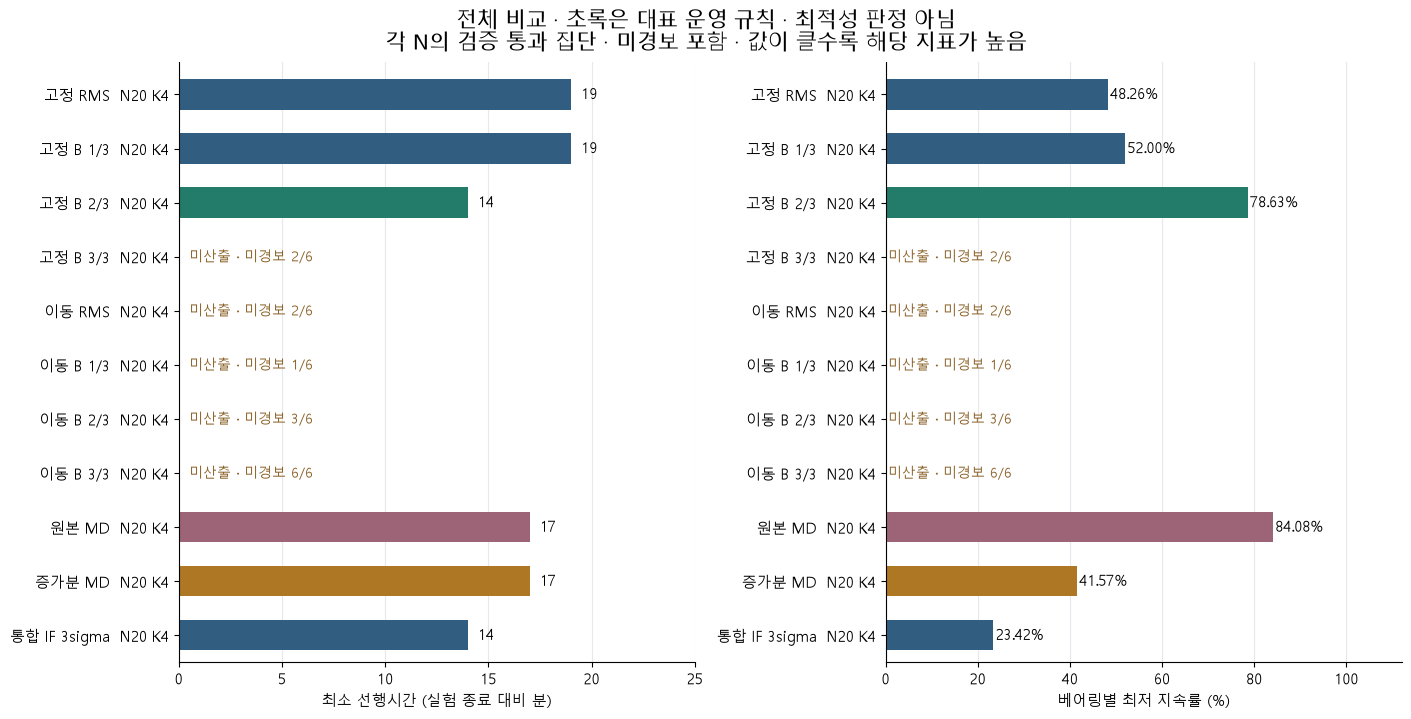

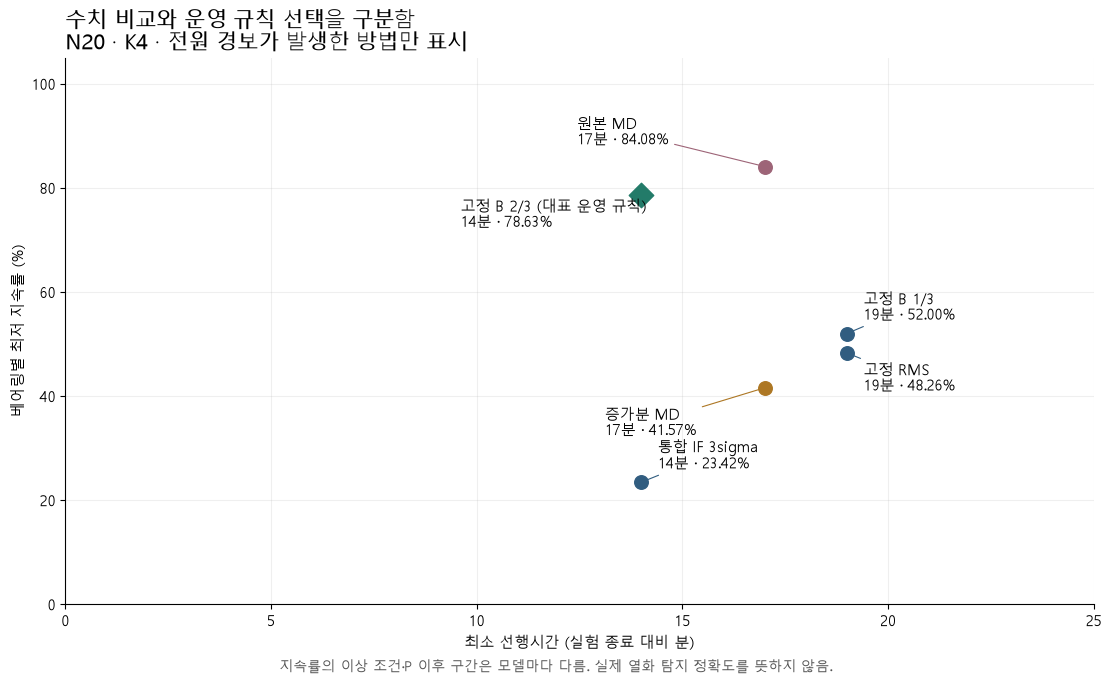

In [ ]:
# 전체 방법은 같은 대상, N=20, K=4, 같은 P/지속률 정의로 비교함.
all_models=build_results(data,cache,passed20,20,
    fixed_specs+moving_specs+md_spec+positive_spec+if_spec)
all_summary=show_results(all_models)

# 대표 규칙은 운영 목적에 따라 명시적으로 지정함. 최고 점수를 뽑는 코드가 아님.
rep_mask=(all_summary.detector.eq("fixed") & all_summary.m_of_3.eq(2) &
          all_summary.baseline_n.eq(20) & all_summary.k.eq(4) &
          all_summary.alarm_mode.eq("consecutive"))
assert rep_mask.sum()==1
representative=all_summary.loc[rep_mask].iloc[0]
rep=all_models[(all_models.detector=="fixed") & all_models.m_of_3.eq(2)]
display(rep[DETAIL_COLS].rename(columns=LABELS).round(2))

def stat(det,m):
    return all_summary[(all_summary.detector==det)&(all_summary.m_of_3==m)].iloc[0]
rms,b1,b2,b3= [stat("fixed",m) for m in range(4)]
original,pos=stat("mahalanobis",3),stat("md_positive",3)
integrated_if=stat("if_3sigma",3)
reason_lines=[
    "선택의 성격: N20·연속4회·고정 B 2/3은 대표 운영 규칙임. 최적 모델로 판정한 것이 아님.",
    "운영 목적: 초기 상한 초과가 같은 축의 여러 특징에서 연속 확인되는 경우를 경보로 설명함.",
    f"대표 규칙 결과: 미경보 {int(b2.no_alarm_count)}/{int(b2.population)}, "
    f"종료 대비 최소 선행 {b2.min_lead_time_min:.0f}분, 최저 지속률 {b2.min_persistence_pct:.2f}%.",
    f"RMS 단독 대비: 최소 선행 {b2.min_lead_time_min-rms.min_lead_time_min:+.0f}분, "
    f"최저 지속률 {b2.min_persistence_pct-rms.min_persistence_pct:+.2f}%p.",
    f"B 1/3 대비: 최소 선행 {b2.min_lead_time_min-b1.min_lead_time_min:+.0f}분, "
    f"최저 지속률 {b2.min_persistence_pct-b1.min_persistence_pct:+.2f}%p.",
    f"B 3/3은 {int(b3.no_alarm_count)}/{int(b3.population)} 미경보. B 2/3은 비교 집단 모두에서 경보.",
    f"원본 MD도 그대로 제시함: 최소 선행 {original.min_lead_time_min:.0f}분, "
    f"최저 지속률 {original.min_persistence_pct:.2f}%. B 2/3보다 두 수치가 높음.",
    f"증가분 MD: 최소 선행 {pos.min_lead_time_min:.0f}분, 최저 지속률 {pos.min_persistence_pct:.2f}%. "
    "기존 상한을 재사용한 수정 규칙이므로 성능 차이를 방향성만의 인과효과로 단정하지 않음.",
    "원본 MD는 감소·조합 변화도 포착함. 이 변화가 정상 또는 오경보라는 뜻은 아니며 별도 상태 변화 정보임.",
    "증가분은 초기 평균 대비 양의 편차임. 고장까지 실험했다는 사실이 모든 특징의 단조 증가를 보장하지 않음.",
    "특징별 상한과 연속 횟수로 경보를 설명할 수 있음. RMS와 Peak는 독립된 두 증거로 해석하지 않음.",
    "모델별 지속률은 서로 다른 이상 조건과 P 이후 구간에서 계산됨. 탐지 정확도나 고장 위험 확률이 아님.",
    "Bearing3_2에서는 RMS P172, B 2/3 P2029로 조기성 손실이 큼. 전체 최소값 차이 5분과 구별해야 함.",
    "IF 자동·직접 모두 P는 네 번째 확인 시점임. 직접 IF의 Bearing1_5는 35~38번째 초과로 P38임.",
    f"6변수 통합 IF 직접 3σ(트리100·ddof=1): 미경보 {int(integrated_if.no_alarm_count)}/{int(integrated_if.population)}, "
    f"최소 선행 {integrated_if.min_lead_time_min:.0f}분, 최저 통합 지속률 {integrated_if.min_persistence_pct:.2f}%. "
    "자동 IF는 6번에서만 별도 비교하며 최초 경보축은 산출하지 않음.",
    "N20·K4는 공통 팀 설정임. MK 통과는 정상 인증이 아니며 결과는 선별된 6개에 한정됨.",
    "실제 결함 시작 라벨이 없어 더 이른 P를 정답으로 볼 수 없음. 실제 열화 탐지의 최적성을 확정하지 않음.",
]
display(Markdown("\n\n".join(reason_lines)))
operating_row=all_summary.loc[rep_mask].assign(
    row_type="operating_rule",selection_basis="operational_objective",
    operating_role="대표 운영 규칙",optimality_claim=False)
reasons=pd.DataFrame({"row_type":"selection_reason",
    "reason_no":range(1,len(reason_lines)+1),"reason_text":reason_lines})
key="10_representative_operating_rule"
sections[key]=pd.concat([all_summary.assign(row_type="summary"),
    all_models.assign(row_type="bearing"),operating_row,reasons],ignore_index=True).assign(analysis_section=key)
section_details[10],section_summaries[10]=all_models,all_summary
compare_plot(all_summary,"전체 비교 · 초록은 대표 운영 규칙 · 최적성 판정 아님","10_all_models")

# 동일 두 지표를 산출할 수 있는 모든 후보를 표시함. 원본 MD도 숨기지 않음.
plot_rows=all_summary[all_summary.all_before_end].copy()
fig,ax=plt.subplots(figsize=(11,6.5),layout="constrained")
offsets={("fixed",0):(12,-27),("fixed",1):(12,10),("fixed",2):(-130,-23),
         ("mahalanobis",3):(-135,16),("md_positive",3):(-115,-34),
         ("if_3sigma",3):(12,10)}
for r in plot_rows.itertuples():
    operating=r.detector=="fixed" and r.m_of_3==2
    color=COLORS["selected"] if operating else COLORS["original_md"] if r.detector=="mahalanobis" else COLORS["positive_md"] if r.detector=="md_positive" else COLORS["reference"]
    ax.scatter(r.min_lead_time_min,r.min_persistence_pct,s=155 if operating else 95,
               color=color,marker="D" if operating else "o",zorder=3)
    label=r.model+(" (대표 운영 규칙)" if operating else "")
    ax.annotate(f"{label}\n{r.min_lead_time_min:.0f}분 · {r.min_persistence_pct:.2f}%",
        (r.min_lead_time_min,r.min_persistence_pct),
        xytext=offsets.get((r.detector,r.m_of_3),(12,10)),textcoords="offset points",fontsize=11,
        arrowprops=dict(arrowstyle="-",color=color,lw=.8))
ax.set(xlim=(0,25),ylim=(0,105),xlabel="최소 선행시간 (실험 종료 대비 분)",
       ylabel="베어링별 최저 지속률 (%)")
ax.grid(alpha=.2)
ax.set_title("수치 비교와 운영 규칙 선택을 구분함\nN20 · K4 · 전원 경보가 발생한 방법만 표시",loc="left",fontsize=15)
fig.text(.5,-.025,"지속률의 이상 조건·P 이후 구간은 모델마다 다름. 실제 열화 탐지 정확도를 뜻하지 않음.",
         ha="center",fontsize=10,color="#555555")
finish_plot(fig,"10_operating_rule_comparison")


## 계산 검산
P 오프바이원, 축 혼합, 미래 자료 누출, 시점별 지속률 분모와 원본 결과 재현을 확인함.
통합 IF가 Nx1이며 축 지표를 만들지 않는지, 직접 상한이 ddof=1인지도 확인함.


In [ ]:
assert len(baseline)==46*15
assert len(passed20)==6 and len(passed15)==8 and len(common)==6
assert set(md_comparison.model)=={"원본 MD","증가분 MD","고정 B 2/3"}
# 35~38번째가 연속 초과이면 P=38. 자동/수동 IF도 동일 함수 경로를 사용함.
probe=np.zeros((45,2),dtype=bool)
probe[34:38,0]=True
row=evaluate_rule(np.arange(1,46),probe,count_conditions(probe,20,"consecutive")>=4)
assert row["t_P"]==38 and row["lead_time_min"]==7
joint_probe=probe[:, :1]
joint_row=evaluate_rule(np.arange(1,46),joint_probe,count_conditions(joint_probe,20,"consecutive")>=4)
assert joint_row["t_P"]==38 and joint_row["first_alarm_axis"]=="not_applicable"
axis_fields=["t_P_H","t_P_V","H_persistence_pct","V_persistence_pct","first_axis_persistence_pct"]
assert all(np.isnan(joint_row[key]) for key in axis_fields)
assert IF_TREES==100 and IF_THRESHOLD_DDOF==1
assert if_comparison.groupby("baseline_n").bearing.nunique().to_dict()=={15:8,20:6}
assert set(if_comparison.k)==set(range(1,9))
assert (if_comparison.monitoring_start_observation==if_comparison.baseline_n+1).all()
assert common_results.bearing.nunique()==6 and common_results.monitoring_start_observation.eq(21).all()
for (bearing,n),scores in cache.items():
    assert scores["if_score"].shape[1]==1 and scores["if_auto"].shape[1]==1
    initial=scores["if_score"][:n,0]
    np.testing.assert_allclose(scores["if_upper"],[initial.mean()+3*initial.std(ddof=1)])
    x=data.loc[data.bearing.eq(bearing),FEATURE_COLUMNS].to_numpy().reshape(-1,2,3)
    for a in range(2):
        centered=x[:,a]-x[:n,a].mean(0)
        cov=np.cov(x[:n,a],rowvar=False,ddof=1)
        for key,dev in [("md",centered),("md_positive",np.maximum(centered,0))]:
            direct=np.einsum("ij,ji->i",dev,np.linalg.solve(cov,dev.T))
            np.testing.assert_allclose(scores[key][:,a],direct,rtol=1e-7,atol=1e-7)
    nonpositive=(scores["fixed"]<=0).all(2)
    np.testing.assert_allclose(scores["md_positive"][nonpositive],0,atol=1e-12)
    windows=np.lib.stride_tricks.sliding_window_view(x,n,axis=0)[:-1]
    direct=(x[n:]-windows.mean(-1))/windows.std(-1,ddof=1)
    np.testing.assert_allclose(scores["moving"][n:],direct,rtol=2e-7,atol=2e-8)
    # IF의 P가 K번째 확인인지 원시 초과 구간으로 별도 검산함.
    for detector in ["if_auto","if_3sigma","mahalanobis","md_positive"]:
        raw,confirmed=rule_flags(scores,detector,3,n,4,"consecutive")
        independent=np.zeros_like(raw)
        independent[n+3:]=np.lib.stride_tricks.sliding_window_view(raw[n:],4,axis=0).all(-1)
        np.testing.assert_array_equal(confirmed,independent)
    for kind in ["fixed","moving"]:
        p=scores[kind]>3
        ind=np.zeros_like(p)
        ind[n+3:]=np.lib.stride_tricks.sliding_window_view(p[n:],4,axis=0).all(-1)
        for m in range(4):
            _,c=rule_flags(scores,kind,m,n,4,"consecutive")
            np.testing.assert_array_equal(c,ind[:,:,0] if m==0 else ind.sum(2)>=m)
for table in section_details.values():
    integrated_rows=table[table.detector.str.startswith("if_")]
    assert integrated_rows.first_alarm_axis.eq("not_applicable").all()
    assert integrated_rows[axis_fields].isna().all().all()
    missing=table.alarm_state.eq("no_alarm")
    assert table.loc[missing,["t_P","lead_time_min","persistence_pct"]].isna().all().all()
    g=table[~missing]
    np.testing.assert_allclose(g.persistence_pct,g.abnormal_observations/g.post_P_observations*100)
    assert (g.post_P_observations==g.end_observation-g.t_P+1).all()
    assert (g.t_P>=g.monitoring_start_observation+g.k-1).all()
    assert not table.duplicated(["bearing",*GROUP_KEYS]).any()
px=data.loc[data.bearing.eq("Bearing3_4"),FEATURE_COLUMNS].to_numpy().reshape(-1,2,3)
prefix=fit_scores(px[:100],20)
for key in ["fixed","moving","md","md_positive","if_score","if_auto"]:
    np.testing.assert_allclose(prefix[key],cache["Bearing3_4",20][key][:100],equal_nan=True,rtol=1e-10,atol=1e-10)
assert hashlib.sha256(DATA_ROOT.read_bytes()).hexdigest()==input_sha256
print("검산 통과: 통합 IF100·ddof1·P=네 번째 확인, B 축·특징 순서, 증가분 거리, Moving 과거창, 미래 절단, 미경보·분모")
assert len(sections)==10
assert representative.detector=="fixed" and representative.m_of_3==2
assert len(rep)==len(passed20)
assert (operating_row.optimality_claim == False).all()
assert original.min_lead_time_min > b2.min_lead_time_min
assert original.min_persistence_pct > b2.min_persistence_pct


검산 통과: 통합 IF100·ddof1·P=네 번째 확인, B 축·특징 순서, 증가분 거리, Moving 과거창, 미래 절단, 미경보·분모


## CSV 10개와 그림 저장

`results/xjtu_operating_rule/`에는 01~10번 CSV를 UTF-8 BOM으로 저장함. `figures/xjtu_operating_rule/`의 PNG는 각 분석 단계에서 생성함.
10번 CSV의 `operating_rule` 행은 목적에 따른 선택, `selection_reason` 행은 선택 근거임.
계산 설정은 `reports/xjtu_operating_rule/analysis_protocol.json`과 아래 출력에 남기며 공유용 설명은 `reports/xjtu_operating_rule/`에서 확인할 수 있음.

공통 지표 컬럼은 `persistence_pct` / `abnormal_observations`임. `signal_combination`으로
H/V OR와 통합 IF를 구별하며, IF의 `first_alarm_axis=not_applicable`이고 축별 수치는 빈 값임.
`m_of_3`는 Z-score 계열에서만 결합 특징 수를 뜻하며 MD·IF의 3은 기존 내부 명세 식별값임.


In [ ]:
# CSV별 row_type으로 집계·베어링별 결과·설명 행을 구분함.
assert len(sections)==10
for key,frame in sections.items():
    frame.to_csv(OUTPUT_DIR_STATS/f"{key}.csv",index=False,encoding="utf-8-sig")
protocol=dict(
    source="DATA/features/XJTU_SY_total_features.csv",source_sha256=input_sha256,
    input_rows=len(data),input_bearings=int(data.bearing.nunique()),feature_columns=FEATURE_COLUMNS,
    baseline_candidates=list(range(5,51)),mk_alpha=MK_ALPHA,baseline_gate="H/V RMS and kurtosis all p>=0.01",
    passed_N20=passed20,passed_N15=passed15,common_passed=common,
    N=20,K=4,common_monitoring_start=21,P="Kth confirmation, 1-based observation",
    md_positive="max(Z,0), original baseline covariance and original predictive F threshold",
    md_positive_calibration="modified rule; original F false-alarm calibration not established",
    if_parameters=dict(features_total=6,models_per_bearing=1,axis_combination="integrated",
                       n_estimators=IF_TREES,max_samples="N",random_state=RANDOM_STATE,
                       n_jobs=1,contamination="auto",scaling="baseline standardized, ddof=1",
                       threshold_sd_ddof=IF_THRESHOLD_DDOF),
    if_comparison=dict(N=[15,20],K=list(range(1,9)),population="independently MK-passed",
                       population_counts={15:len(passed15),20:len(passed20)},
                       monitoring_start_observation={15:16,20:21},
                       common_comparison_section=8,common_monitoring_start_observation=21),
    if_manual="mean(-training score_samples)+3*sample SD(ddof=1)",
    persistence="current anomaly fraction from P inclusive; Z/MD H/V OR; IF integrated; no latch",
    first_axis_tie="axis models: arithmetic mean of H/V persistence; IF: not_applicable and axis metrics NaN",selection="explicit operational objective; no score-based optimizer",
    representative_operating_rule=dict(model=representative.model,N=20,K=4,purpose="sustained upper-limit exceedance across features",optimality_claim=False),
    versions=dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,
                  scipy=scipy.__version__,sklearn=sklearn.__version__))

REPORT_DIR = PROJECT_ROOT / "reports" / "xjtu_operating_rule"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
PROTOCOL_PATH = REPORT_DIR / "analysis_protocol.json"
PROTOCOL_PATH.write_text(json.dumps(protocol,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
display(Markdown("**실행 설정**"))
print(json.dumps(protocol,ensure_ascii=False,indent=2))
print(f"저장 완료: {OUTPUT_DIR_STATS} / CSV {len(sections)}개")
print(f"그림 경로: {FIGURE_DIR}")

print(f"계산 설정: {PROTOCOL_PATH}")


{
  "source": "DATA/features/XJTU_SY_total_features.csv",
  "source_sha256": "1cd73c3c41cd7dfb0f2fd6ca21841157d92edfd71606ffb7d0856938a696f8fb",
  "input_rows": 9216,
  "input_bearings": 15,
  "feature_columns": [
    "horizontal_rms",
    "horizontal_kurtosis",
    "horizontal_peak",
    "vertical_rms",
    "vertical_kurtosis",
    "vertical_peak"
  ],
  "baseline_candidates": [
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    44,
    45,
    46,
    47,
    48,
    49,
    50
  ],
  "mk_alpha": 0.01,
  "baseline_gate": "H/V RMS and kurtosis all p>=0.01",
  "passed_N20": [
    "Bearing1_5",
    "Bearing2_1",
    "Bearing2_2",
    "Bearing2_3",
    "Bearing3_2",
    "Bearing3_4"
  ],
  "passed_N15": [
    "Bearing1_3",
    "Bear

**실행 설정**